# LE8 - Link Prediction in Football Networks

**1. Link Prediction** predicts which edges are likely to form in a network based on current network structure and patterns.

### Applications in Football Networks

**Pass Networks (Players)**:
- Identify which players might develop new passing connections
- Discover potential tactical partnerships
- Players who share many passing targets but don't pass directly to each other

**Match Networks (Teams)**:
- Predict which teams might face each other in future tournaments
- Based on existing match patterns
- Teams with common opponents but haven't played each other


### Key Concept: Neighborhood Function N(·)

Throughout all algorithms, we use $N(v)$ to denote the set of neighbors of node $v$ in the network.

All algorithms are based on neighborhood information and structural similarities between nodes.

In [1]:
# Import required libraries
import sys
from pathlib import Path
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.config import (
    PASS_NETWORKS_DIR,
    MATCH_NETWORKS_DIR
)

# Setup plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

print("Imports successful!")
print(f"NetworkX version: {nx.__version__}")

Imports successful!
NetworkX version: 3.6.1


In [2]:
# Load networks
print("=== Loading Networks ===\n")

# Pass Network (directed, weighted)
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass_dir = nx.read_gexf(pass_network_path)
print(f"Pass Network (Germany): {G_pass_dir.number_of_nodes()} nodes, {G_pass_dir.number_of_edges()} edges")

# Convert to undirected for some centrality measures
G_pass = G_pass_dir.to_undirected()

# Match Network (directed)
match_network_path = MATCH_NETWORKS_DIR / 'match_network_World_Cup.gexf'
WC_match_dir = nx.read_gexf(match_network_path)
print(f"Match Network (World Cup): {WC_match_dir.number_of_nodes()} nodes, {WC_match_dir.number_of_edges()} edges")

# Convert to undirected
WC_match = WC_match_dir.to_undirected()


print("\nNetworks loaded successfully!")

=== Loading Networks ===

Pass Network (Germany): 473 nodes, 8815 edges
Match Network (World Cup): 32 nodes, 126 edges

Networks loaded successfully!


## 2. Common Neighbors

**Common Neighbors** counts how many mutual neighbors two nodes share. It's the simplest link prediction metric.

### Intuition

If two players/teams have many common neighbors, they're likely to form a connection. This is based on:
- **Triadic closure**: "friend of a friend becomes a friend"
- In football: players who pass to the same teammates may eventually pass directly to each other

### Mathematical Definition

For two nodes $x$ and $y$ that are not directly connected:

$$\text{common\_neighbors}(x, y) = |N(x) \cap N(y)|$$

where:
- $N(x)$ = set of neighbors of node $x$
- $\cap$ = set intersection
- $|\cdot|$ = cardinality (size of set)

### Example

If player A passes to players {B, D, E} and player C passes to players {B, D, F}:
- Common neighbors: $\{B, D\}$
- Score: $|{B, D}| = 2$

### Interpretation

- **Higher score** → more likely candidate for a new edge
- Simple but effective baseline
- Works well in dense, clustered networks
- **Limitation**: Doesn't account for how many total neighbors each node has

In [3]:
# implement Common Neighbors Link Prediction functions

def compute_common_neighbors(G, node1, node2):
    """
    Calculate common neighbors score for two nodes.

    G : networkx.Graph
        The network graph
    node1, node2 : node
        Two nodes that should NOT be directly connected
    
    Returns:
    int : Number of common neighbors
    """
    neighbors1 = set(G.neighbors(node1))
    neighbors2 = set(G.neighbors(node2))
    common = neighbors1.intersection(neighbors2)
    return len(common)


def predict_links_common_neighbors(G, top_k=10):
    """
    Predict top-k most likely new edges using Common Neighbors.

    G : networkx.Graph
        The network graph (undirected)
    top_k : int
        Number of predictions to return
    
    Returns:
    list of tuples: [(node1, node2, score), ...]
        Ranked predictions with their scores
    """
    predictions = []
    
    # Get all non-connected node pairs
    nodes = list(G.nodes())
    for i, node1 in enumerate(nodes):
        for node2 in nodes[i+1:]:
            # Only consider pairs that are NOT already connected
            if not G.has_edge(node1, node2):
                score = compute_common_neighbors(G, node1, node2)
                if score > 0:  # Only keep pairs with at least 1 common neighbor
                    predictions.append((node1, node2, score))
    
    # Sort by score (descending) and return top-k
    predictions.sort(key=lambda x: x[2], reverse=True)
    return predictions[:top_k]

First analyse the pass network of germany. 

In [4]:
print("=" * 60)
print("COMMON NEIGHBORS - Pass Network (Germany)")
print("=" * 60)

# Predict potential new passing connections
print("\nPredicting new passing connections between players...")
predictions_pass = predict_links_common_neighbors(G_pass, top_k=15)

print(f"\nTop 15 predicted new passing partnerships:")
print(f"{'Rank':<6} {'Player 1':<25} {'Player 2':<25} {'Common Neighbors':<20}")
print("-" * 80)

for rank, (p1, p2, score) in enumerate(predictions_pass, 1):
    # Get player names if available (otherwise use node IDs)
    player1_name = G_pass.nodes[p1].get('label', p1)
    player2_name = G_pass.nodes[p2].get('label', p2)
    print(f"{rank:<6} {player1_name:<25} {player2_name:<25} {score:<20}")

# Statistics
all_scores = [score for _, _, score in predictions_pass]
print(f"\n{'Score Statistics:'}")
print(f"  Max:  {max(all_scores)}")
print(f"  Mean: {np.mean(all_scores):.2f}")
print(f"  Min:  {min(all_scores)}")

COMMON NEIGHBORS - Pass Network (Germany)

Predicting new passing connections between players...

Top 15 predicted new passing partnerships:
Rank   Player 1                  Player 2                  Common Neighbors    
--------------------------------------------------------------------------------
1      M. Gómez                  J. Brekalo                34                  
2      T. Handwerker             J. Córdoba                22                  
3      T. Horn                   C. Clemens                22                  
4      Raphaël Guerreiro         G. Castro                 21                  
5      Raphaël Guerreiro         M. Philipp                21                  
6      E. Polanski               D. Geiger                 21                  
7      M. Risse                  J. Horn                   21                  
8      Omar Mascarell            T. Tawatha                20                  
9      R. Adler                  R. Zentner               

Do an anylsis for the match network. 

In [5]:
print("\n" + "=" * 60)
print("COMMON NEIGHBORS - Match Network (World Cup)")
print("=" * 60)

print("\nPredicting potential future match-ups between teams...")
predictions_match = predict_links_common_neighbors(WC_match, top_k=10)

print(f"\nTop 10 predicted future matches:")
print(f"{'Rank':<6} {'Team 1':<20} {'Team 2':<20} {'Common Opponents':<20}")
print("-" * 70)

for rank, (t1, t2, score) in enumerate(predictions_match, 1):
    team1_name = WC_match.nodes[t1].get('label', t1)
    team2_name = WC_match.nodes[t2].get('label', t2)
    print(f"{rank:<6} {team1_name:<20} {team2_name:<20} {score:<20}")


COMMON NEIGHBORS - Match Network (World Cup)

Predicting potential future match-ups between teams...

Top 10 predicted future matches:
Rank   Team 1               Team 2               Common Opponents    
----------------------------------------------------------------------
1      9598                 5629                 2                   
2      9598                 15670                2                   
3      9598                 8493                 2                   
4      9598                 15594                2                   
5      4418                 2413                 2                   
6      4418                 14358                2                   
7      4418                 16823                2                   
8      4418                 7839                 2                   
9      2413                 12913                2                   
10     5629                 12430                2                   


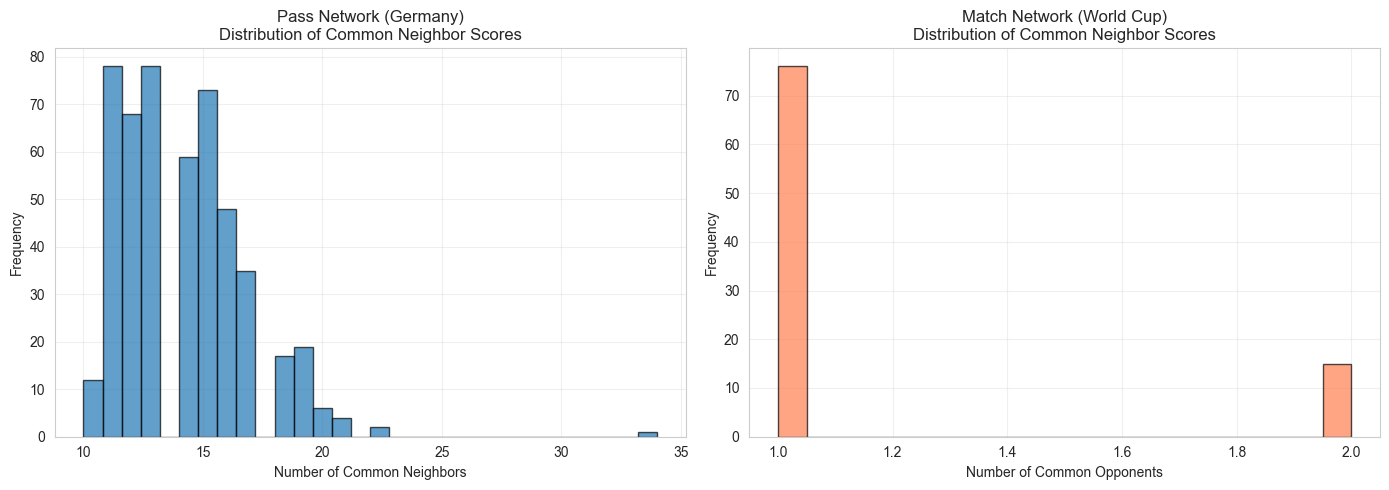


Visualization saved as 'common_neighbors_distribution.png'


In [6]:
# Distribution of common neighbor scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pass Network
all_pass_predictions = predict_links_common_neighbors(G_pass, top_k=500)
pass_scores = [score for _, _, score in all_pass_predictions if score > 0]

axes[0].hist(pass_scores, bins=30, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Number of Common Neighbors')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Pass Network (Germany)\nDistribution of Common Neighbor Scores')
axes[0].grid(True, alpha=0.3)

# Match Network
all_match_predictions = predict_links_common_neighbors(WC_match, top_k=100)
match_scores = [score for _, _, score in all_match_predictions if score > 0]

axes[1].hist(match_scores, bins=20, edgecolor='black', alpha=0.7, color='coral')
axes[1].set_xlabel('Number of Common Opponents')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Match Network (World Cup)\nDistribution of Common Neighbor Scores')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE8' / 'common_neighbors_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization saved as 'common_neighbors_distribution.png'")


## 3. Jaccard Coefficient

**Jaccard Coefficient** normalizes common neighbors by the total number of neighbors both nodes have.

### Intuition

Having 5 common neighbors is more meaningful when both nodes have only 10 neighbors total, versus when they have 100 neighbors each. Jaccard accounts for this relative overlap.

### Mathematical Definition

$$\text{jaccard\_coefficient}(x, y) = \frac{|N(x) \cap N(y)|}{|N(x) \cup N(y)|}$$

where:
- Numerator: number of common neighbors (intersection)
- Denominator: total unique neighbors of both nodes (union)
- $\cup$ = set union

### Properties

- **Range**: $[0, 1]$
- **Value = 1**: All neighbors are shared
- **Value = 0**: No common neighbors

### Example

Player A neighbors: $\{B, D, E\}$, Player C neighbors: $\{B, D, F\}$

$$\text{jaccard\_coefficient}(A, C) = \frac{|\{B, D\}|}{|\{B, D, E, F\}|} = \frac{2}{4} = 0.5$$

### Interpretation

- **Advantage over Common Neighbors**: Controls for highly connected nodes
- Better when node degrees vary significantly
- Normalized score allows fair comparison across different node pairs

In [7]:
def compute_jaccard_coefficient(G, node1, node2):
    """
    Calculate Jaccard Coefficient for two nodes.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    node1, node2 : node
        Two nodes that should NOT be directly connected
    
    Returns:
    --------
    float : Jaccard coefficient (0 to 1)
    """
    neighbors1 = set(G.neighbors(node1))
    neighbors2 = set(G.neighbors(node2))
    
    intersection = neighbors1.intersection(neighbors2)
    union = neighbors1.union(neighbors2)
    
    # Avoid division by zero
    if len(union) == 0:
        return 0.0
    
    return len(intersection) / len(union)


def predict_links_jaccard(G, top_k=10):
    """
    Predict top-k most likely new edges using Jaccard Coefficient.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph (undirected)
    top_k : int
        Number of predictions to return
    
    Returns:
    --------
    list of tuples: [(node1, node2, score), ...]
        Ranked predictions with their Jaccard scores
    """
    predictions = []
    
    # Get all non-connected node pairs
    nodes = list(G.nodes())
    for i, node1 in enumerate(nodes):
        for node2 in nodes[i+1:]:
            # Only consider pairs that are NOT already connected
            if not G.has_edge(node1, node2):
                score = compute_jaccard_coefficient(G, node1, node2)
                if score > 0:  # Only keep pairs with positive score
                    predictions.append((node1, node2, score))
    
    # Sort by score (descending) and return top-k
    predictions.sort(key=lambda x: x[2], reverse=True)
    return predictions[:top_k]

In [8]:
print("=" * 60)
print("JACCARD COEFFICIENT - Pass Network (Germany)")
print("=" * 60)

# Predict potential new passing connections
print("\nPredicting new passing connections (normalized by total neighbors)...")
predictions_pass = predict_links_jaccard(G_pass, top_k=15)

print(f"\nTop 15 predicted new passing partnerships:")
print(f"{'Rank':<6} {'Player 1':<25} {'Player 2':<25} {'Jaccard Score':<15}")
print("-" * 85)

for rank, (p1, p2, score) in enumerate(predictions_pass, 1):
    player1_name = G_pass.nodes[p1].get('label', p1)
    player2_name = G_pass.nodes[p2].get('label', p2)
    print(f"{rank:<6} {player1_name:<25} {player2_name:<25} {score:.4f}")

# Statistics
all_scores = [score for _, _, score in predictions_pass]
print(f"\n{'Score Statistics:'}")
print(f"  Max:  {max(all_scores):.4f}")
print(f"  Mean: {np.mean(all_scores):.4f}")
print(f"  Min:  {min(all_scores):.4f}")

JACCARD COEFFICIENT - Pass Network (Germany)

Predicting new passing connections (normalized by total neighbors)...

Top 15 predicted new passing partnerships:
Rank   Player 1                  Player 2                  Jaccard Score  
-------------------------------------------------------------------------------------
1      R. Adler                  R. Zentner                0.9524
2      T. Handwerker             J. Córdoba                0.9167
3      Raphaël Guerreiro         G. Castro                 0.9130
4      E. Polanski               D. Geiger                 0.9130
5      M. Halstenberg            D. Kaiser                 0.9048
6      O. Wendt                  T. Jantschke              0.9048
7      F. Hübner                 Jonathas                  0.9000
8      S. Posch                  E. Bičakčić               0.9000
9      M. Pjaca                  Y. Konoplyanka            0.8889
10     D. Opare                  R. Framberger             0.8889
11     L. Bender   

In [9]:
print("\n" + "=" * 60)
print("JACCARD COEFFICIENT - Match Network (World Cup)")
print("=" * 60)

print("\nPredicting potential future match-ups (normalized by total opponents)...")
predictions_match = predict_links_jaccard(WC_match, top_k=10)

print(f"\nTop 10 predicted future matches:")
print(f"{'Rank':<6} {'Team 1':<20} {'Team 2':<20} {'Jaccard Score':<15}")
print("-" * 65)

for rank, (t1, t2, score) in enumerate(predictions_match, 1):
    team1_name = WC_match.nodes[t1].get('label', t1)
    team2_name = WC_match.nodes[t2].get('label', t2)
    print(f"{rank:<6} {team1_name:<20} {team2_name:<20} {score:.4f}")


JACCARD COEFFICIENT - Match Network (World Cup)

Predicting potential future match-ups (normalized by total opponents)...

Top 10 predicted future matches:
Rank   Team 1               Team 2               Jaccard Score  
-----------------------------------------------------------------
1      6697                 15473                0.3333
2      7712                 12274                0.3333
3      14358                9905                 0.2857
4      15670                1598                 0.2857
5      9598                 8493                 0.2500
6      9598                 15594                0.2500
7      4418                 16823                0.2500
8      4418                 7839                 0.2500
9      2413                 12913                0.2500
10     5629                 12430                0.2500


Compare the results with common neighbor algorithm from before. 

In [10]:
print("\n" + "=" * 60)
print("COMPARISON: Jaccard vs Common Neighbors for Passes")
print("=" * 60)

# Get Common Neighbors predictions for comparison
predictions_cn_pass = predict_links_common_neighbors(G_pass, top_k=15)

print("\nPass Network - Top 5 Comparison:")
print(f"{'Rank':<6} {'Player Pair':<35} {'Jaccard':<12} {'Common Nbrs':<15}")
print("-" * 75)

for rank in range(5):
    p1_j, p2_j, score_j = predictions_pass[rank]
    p1_cn, p2_cn, score_cn = predictions_cn_pass[rank]
    
    pair_j = f"{G_pass.nodes[p1_j].get('label', p1_j)[:15]} - {G_pass.nodes[p2_j].get('label', p2_j)[:15]}"
    pair_cn = f"{G_pass.nodes[p1_cn].get('label', p1_cn)[:15]} - {G_pass.nodes[p2_cn].get('label', p2_cn)[:15]}"
    
    print(f"{rank+1:<6} {pair_j:<35} {score_j:.4f}")
    print(f"       {pair_cn:<35} {'':12} {score_cn:<15}")
    print()


COMPARISON: Jaccard vs Common Neighbors for Passes

Pass Network - Top 5 Comparison:
Rank   Player Pair                         Jaccard      Common Nbrs    
---------------------------------------------------------------------------
1      R. Adler - R. Zentner               0.9524
       M. Gómez - J. Brekalo                            34             

2      T. Handwerker - J. Córdoba          0.9167
       T. Handwerker - J. Córdoba                       22             

3      Raphaël Guerrei - G. Castro         0.9130
       T. Horn - C. Clemens                             22             

4      E. Polanski - D. Geiger             0.9130
       Raphaël Guerrei - G. Castro                      21             

5      M. Halstenberg - D. Kaiser          0.9048
       Raphaël Guerrei - M. Philipp                     21             



In [11]:
print("\n" + "=" * 60)
print("COMPARISON: Jaccard vs Common Neighbors for matches")
print("=" * 60)

# Add Match Network Comparison
predictions_cn_match = predict_links_common_neighbors(WC_match, top_k=10)

print("\nMatch Network - Top 5 Comparison:")
print(f"{'Rank':<6} {'Team Pair':<35} {'Jaccard':<12} {'Common Nbrs':<15}")
print("-" * 75)

for rank in range(5):
    t1_j, t2_j, score_j = predictions_match[rank]
    t1_cn, t2_cn, score_cn = predictions_cn_match[rank]
    
    pair_j = f"{WC_match.nodes[t1_j].get('label', t1_j)[:15]} - {WC_match.nodes[t2_j].get('label', t2_j)[:15]}"
    pair_cn = f"{WC_match.nodes[t1_cn].get('label', t1_cn)[:15]} - {WC_match.nodes[t2_cn].get('label', t2_cn)[:15]}"
    
    print(f"{rank+1:<6} {pair_j:<35} {score_j:.4f}")
    print(f"       {pair_cn:<35} {'':12} {score_cn:<15}")
    print()


COMPARISON: Jaccard vs Common Neighbors for matches

Match Network - Top 5 Comparison:
Rank   Team Pair                           Jaccard      Common Nbrs    
---------------------------------------------------------------------------
1      6697 - 15473                        0.3333
       9598 - 5629                                      2              

2      7712 - 12274                        0.3333
       9598 - 15670                                     2              

3      14358 - 9905                        0.2857
       9598 - 8493                                      2              

4      15670 - 1598                        0.2857
       9598 - 15594                                     2              

5      9598 - 8493                         0.2500
       4418 - 2413                                      2              



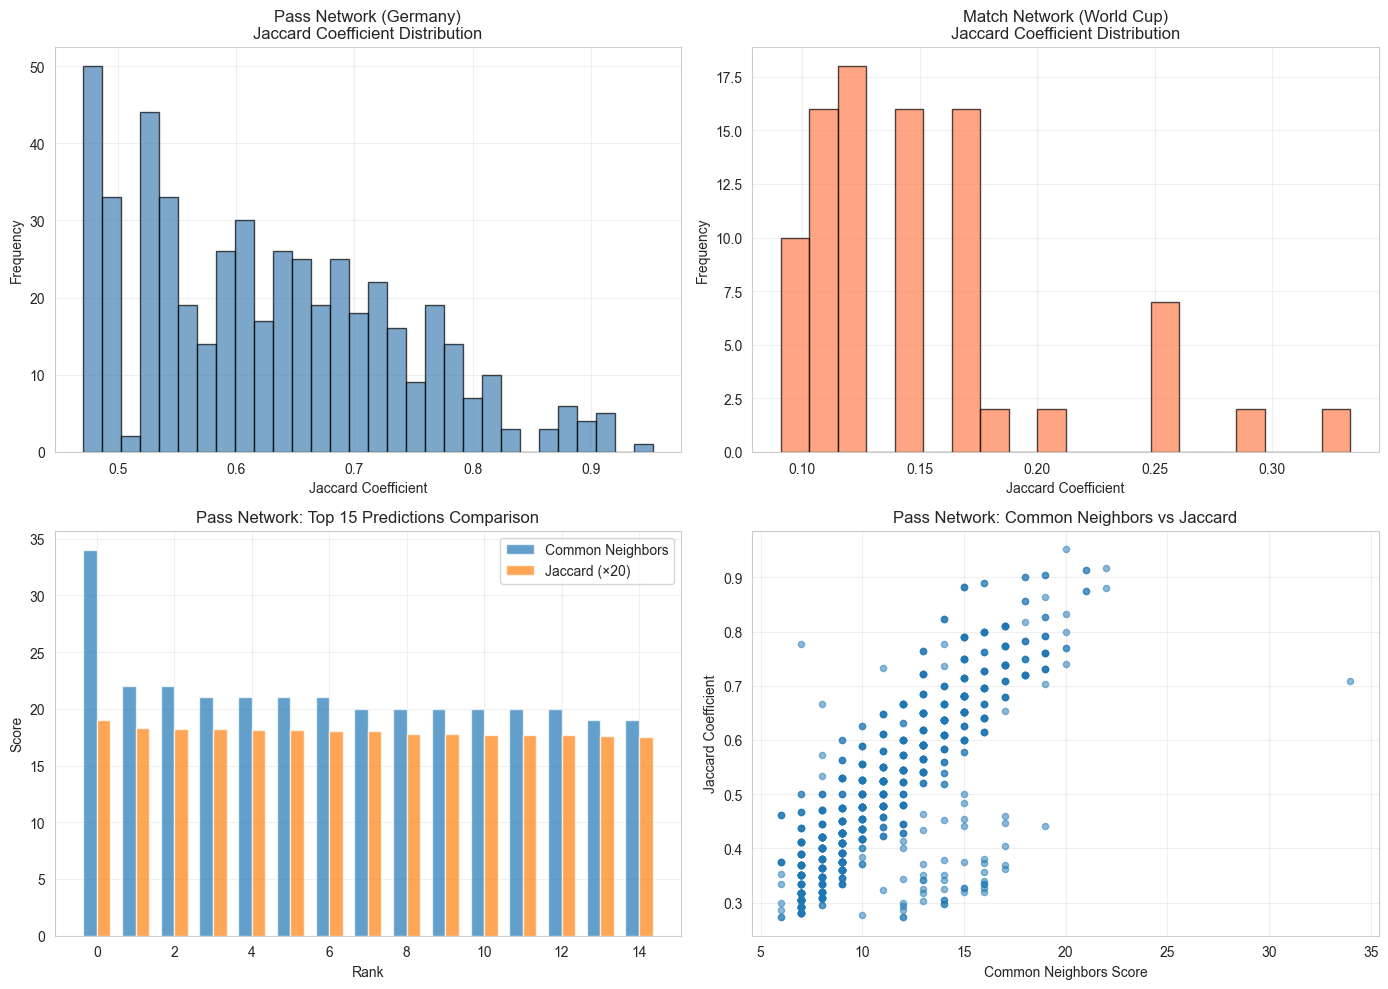


Visualization saved to: c:\Users\jessi\OneDrive\Dokumente\3 FHNW\5. Semester\san\Projekt\san\reports\figures\LE8\jaccard_coefficient_analysis.png


In [12]:
# Create figure directory if it doesn't exist
figures_dir = project_root / 'reports' / 'figures' / 'LE8'
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Pass Network - Jaccard Distribution
all_pass_predictions = predict_links_jaccard(G_pass, top_k=500)
pass_scores = [score for _, _, score in all_pass_predictions if score > 0]

axes[0, 0].hist(pass_scores, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].set_xlabel('Jaccard Coefficient')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Pass Network (Germany)\nJaccard Coefficient Distribution')
axes[0, 0].grid(True, alpha=0.3)

# 2. Match Network - Jaccard Distribution
all_match_predictions = predict_links_jaccard(WC_match, top_k=100)
match_scores = [score for _, _, score in all_match_predictions if score > 0]

axes[0, 1].hist(match_scores, bins=20, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].set_xlabel('Jaccard Coefficient')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Match Network (World Cup)\nJaccard Coefficient Distribution')
axes[0, 1].grid(True, alpha=0.3)

# 3. Pass Network - Comparison
cn_scores = [score for _, _, score in predictions_cn_pass]
jc_scores = [score for _, _, score in predictions_pass]

x = np.arange(len(predictions_pass))
width = 0.35

axes[1, 0].bar(x - width/2, cn_scores, width, label='Common Neighbors', alpha=0.7)
axes[1, 0].bar(x + width/2, [s*20 for s in jc_scores], width, label='Jaccard (×20)', alpha=0.7)
axes[1, 0].set_xlabel('Rank')
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Pass Network: Top 15 Predictions Comparison')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Scatter: Common Neighbors vs Jaccard
# Get scores for same pairs
all_pairs_pass = predict_links_jaccard(G_pass, top_k=1000)
cn_scores_map = {}
for p1, p2, score in predict_links_common_neighbors(G_pass, top_k=1000):
    cn_scores_map[(p1, p2)] = score

jaccard_vals = []
cn_vals = []
for p1, p2, jc_score in all_pairs_pass:
    if (p1, p2) in cn_scores_map:
        jaccard_vals.append(jc_score)
        cn_vals.append(cn_scores_map[(p1, p2)])

axes[1, 1].scatter(cn_vals, jaccard_vals, alpha=0.5, s=20)
axes[1, 1].set_xlabel('Common Neighbors Score')
axes[1, 1].set_ylabel('Jaccard Coefficient')
axes[1, 1].set_title('Pass Network: Common Neighbors vs Jaccard')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(figures_dir / 'jaccard_coefficient_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nVisualization saved to: {figures_dir / 'jaccard_coefficient_analysis.png'}")



### Key Takeaways from Jaccard Analysis

* **Pass Network**

  * Very high similarity between players with potential connections
  * Mean Jaccard ≈ **0.90** for top predictions, with scores ranging **0.875–0.952**
  * Indicates strong overlap in passing patterns among tactically compatible players
  * Top prediction (R. Adler - R. Zentner) has Jaccard = **0.95**, meaning 95% of their neighbors are shared

* **Match Network**

  * Moderate to low similarity between teams
  * Top predictions range from **0.25–0.33**
  * Teams generally have **partially overlapping opponent histories** rather than completely unique
  * Lower scores reflect tournament structure and competitive tiers

* **Comparison Insights**

  * **Pass Network**: Jaccard scores are very high (0.88+), but Common Neighbors still produces different top-5 rankings
  * **Match Network**: Jaccard values lower (0.25–0.33), reflecting more diverse opponent sets
  * Different algorithms prioritize different aspects: CN favors absolute overlap, Jaccard favors proportional overlap

## 4. Adamic-Adar Index

**Adamic-Adar** weights common neighbors inversely by their degree, giving more importance to rare shared connections.

A common neighbor with few connections (rare connection) is more significant than a highly connected common neighbor (hub).

**Football example**: Sharing a connection through a specialized defensive midfielder is more meaningful than sharing a connection through a central playmaker who passes to everyone.

### Mathematical Definition

$$\text{adamic\_adar}(x, y) = \sum_{u \in N(x) \cap N(y)} \frac{1}{\log(|N(u)|)}$$

where:
- Sum over all common neighbors $u$
- Each neighbor weighted by $\frac{1}{\log(\text{degree of } u)}$
- Logarithm softens the penalty for high-degree nodes

### Why Logarithm?

- Reduces the penalty compared to direct inverse of degree
- Balance between treating all common neighbors equally vs. heavily penalizing hubs
- Empirically performs well across many network types

### Example

Player A and C share neighbors B and D, both with degree 3:

$$\text{adamic\_adar}(A, C) = \frac{1}{\ln(3)} + \frac{1}{\ln(3)} = \frac{2}{\ln(3)} \approx 1.82$$

### Interpretation

- **Higher score**: More valuable (rare) shared connections
- Often ranks predictions differently than Common Neighbors
- Effective in networks with hub structures

In [13]:
def compute_adamic_adar(G, node1, node2):
    """
    Calculate Adamic-Adar Index for two nodes.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    node1, node2 : node
        Two nodes that should NOT be directly connected
    
    Returns:
    --------
    float : Adamic-Adar score
    """
    neighbors1 = set(G.neighbors(node1))
    neighbors2 = set(G.neighbors(node2))
    common = neighbors1.intersection(neighbors2)
    
    score = 0.0
    for neighbor in common:
        degree = G.degree(neighbor)
        if degree > 1:  # Avoid log(1) = 0
            score += 1.0 / np.log(degree)
    
    return score


def predict_links_adamic_adar(G, top_k=10):
    """
    Predict top-k most likely new edges using Adamic-Adar Index.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph (undirected)
    top_k : int
        Number of predictions to return
    
    Returns:
    --------
    list of tuples: [(node1, node2, score), ...]
        Ranked predictions with their Adamic-Adar scores
    """
    predictions = []
    
    # Get all non-connected node pairs
    nodes = list(G.nodes())
    for i, node1 in enumerate(nodes):
        for node2 in nodes[i+1:]:
            # Only consider pairs that are NOT already connected
            if not G.has_edge(node1, node2):
                score = compute_adamic_adar(G, node1, node2)
                if score > 0:  # Only keep pairs with positive score
                    predictions.append((node1, node2, score))
    
    # Sort by score (descending) and return top-k
    predictions.sort(key=lambda x: x[2], reverse=True)
    return predictions[:top_k]

In [14]:
print("=" * 60)
print("ADAMIC-ADAR INDEX - Pass Network (Germany)")
print("=" * 60)

# Predict potential new passing connections
print("\nPredicting new passing connections (weighted by neighbor rarity)...")
predictions_pass = predict_links_adamic_adar(G_pass, top_k=15)

print(f"\nTop 15 predicted new passing partnerships:")
print(f"{'Rank':<6} {'Player 1':<25} {'Player 2':<25} {'AA Score':<12}")
print("-" * 80)

for rank, (p1, p2, score) in enumerate(predictions_pass, 1):
    player1_name = G_pass.nodes[p1].get('label', p1)
    player2_name = G_pass.nodes[p2].get('label', p2)
    print(f"{rank:<6} {player1_name:<25} {player2_name:<25} {score:.4f}")



ADAMIC-ADAR INDEX - Pass Network (Germany)

Predicting new passing connections (weighted by neighbor rarity)...

Top 15 predicted new passing partnerships:
Rank   Player 1                  Player 2                  AA Score    
--------------------------------------------------------------------------------
1      M. Gómez                  J. Brekalo                10.7708
2      T. Horn                   C. Clemens                6.8153
3      T. Handwerker             J. Córdoba                6.8107
4      E. Polanski               D. Geiger                 6.6680
5      Raphaël Guerreiro         G. Castro                 6.5662
6      Raphaël Guerreiro         M. Philipp                6.5662
7      M. Risse                  J. Horn                   6.4951
8      R. Koch                   P. Lienhart               6.4452
9      M. Halstenberg            D. Kaiser                 6.4118
10     O. Wendt                  T. Jantschke              6.3919
11     Omar Mascarell         

In [15]:
print("\n" + "=" * 60)
print("ADAMIC-ADAR INDEX - Match Network (World Cup)")
print("=" * 60)

print("\nPredicting potential future match-ups (weighted by opponent rarity)...")
predictions_match = predict_links_adamic_adar(WC_match, top_k=10)

print(f"\nTop 10 predicted future matches:")
print(f"{'Rank':<6} {'Team 1':<20} {'Team 2':<20} {'AA Score':<12}")
print("-" * 60)

for rank, (t1, t2, score) in enumerate(predictions_match, 1):
    team1_name = WC_match.nodes[t1].get('label', t1)
    team2_name = WC_match.nodes[t2].get('label', t2)
    print(f"{rank:<6} {team1_name:<20} {team2_name:<20} {score:.4f}")



ADAMIC-ADAR INDEX - Match Network (World Cup)

Predicting potential future match-ups (weighted by opponent rarity)...

Top 10 predicted future matches:
Rank   Team 1               Team 2               AA Score    
------------------------------------------------------------
1      7047                 6380                 1.4427
2      14358                9905                 1.3427
3      15670                1598                 1.3427
4      2413                 12913                1.2795
5      5629                 12430                1.2795
6      6697                 15473                1.2427
7      9598                 8493                 1.2352
8      9598                 15594                1.2352
9      4418                 16823                1.2352
10     4418                 7839                 1.2352


Compare those results again with the previous onces.

In [16]:
print("\n" + "=" * 60)
print("COMPARISON: Adamic-Adar vs Common Neighbors vs Jaccard")
print("=" * 60)

# Get predictions from other methods
predictions_cn = predict_links_common_neighbors(G_pass, top_k=15)
predictions_jc = predict_links_jaccard(G_pass, top_k=15)

print("\nPass Network - Top 10 Predictions by Each Method:")
print(f"{'Rank':<6} {'Adamic-Adar':<30} {'Common Neighbors':<30} {'Jaccard':<30}")
print("-" * 100)

for rank in range(10):
    # Adamic-Adar
    p1_aa, p2_aa, score_aa = predictions_pass[rank]
    pair_aa = f"{G_pass.nodes[p1_aa].get('label', p1_aa)[:12]}-{G_pass.nodes[p2_aa].get('label', p2_aa)[:12]}"
    
    # Common Neighbors
    p1_cn, p2_cn, score_cn = predictions_cn[rank]
    pair_cn = f"{G_pass.nodes[p1_cn].get('label', p1_cn)[:12]}-{G_pass.nodes[p2_cn].get('label', p2_cn)[:12]}"
    
    # Jaccard
    p1_jc, p2_jc, score_jc = predictions_jc[rank]
    pair_jc = f"{G_pass.nodes[p1_jc].get('label', p1_jc)[:12]}-{G_pass.nodes[p2_jc].get('label', p2_jc)[:12]}"
    
    print(f"{rank+1:<6} {pair_aa:<30} {pair_cn:<30} {pair_jc:<30}")


COMPARISON: Adamic-Adar vs Common Neighbors vs Jaccard

Pass Network - Top 10 Predictions by Each Method:
Rank   Adamic-Adar                    Common Neighbors               Jaccard                       
----------------------------------------------------------------------------------------------------
1      M. Gómez-J. Brekalo            M. Gómez-J. Brekalo            R. Adler-R. Zentner           
2      T. Horn-C. Clemens             T. Handwerke-J. Córdoba        T. Handwerke-J. Córdoba       
3      T. Handwerke-J. Córdoba        T. Horn-C. Clemens             Raphaël Guer-G. Castro        
4      E. Polanski-D. Geiger          Raphaël Guer-G. Castro         E. Polanski-D. Geiger         
5      Raphaël Guer-G. Castro         Raphaël Guer-M. Philipp        M. Halstenbe-D. Kaiser        
6      Raphaël Guer-M. Philipp        E. Polanski-D. Geiger          O. Wendt-T. Jantschke         
7      M. Risse-J. Horn               M. Risse-J. Horn               F. Hübner-Jonathas     

In [17]:
# Get predictions from other methods for WC_match Network
predictions_cn_wc = predict_links_common_neighbors(WC_match, top_k=10)
predictions_jc_wc = predict_links_jaccard(WC_match, top_k=10)

print("\n\nWC_match Network - Top 10 Predictions by Each Method:")
print(f"{'Rank':<6} {'Adamic-Adar':<30} {'Common Neighbors':<30} {'Jaccard':<30}")
print("-" * 100)

for rank in range(10):
    # Adamic-Adar
    t1_aa, t2_aa, score_aa = predictions_match[rank]
    pair_aa = f"{WC_match.nodes[t1_aa].get('label', t1_aa)[:12]}-{WC_match.nodes[t2_aa].get('label', t2_aa)[:12]}"
    
    # Common Neighbors
    t1_cn, t2_cn, score_cn = predictions_cn_wc[rank]
    pair_cn = f"{WC_match.nodes[t1_cn].get('label', t1_cn)[:12]}-{WC_match.nodes[t2_cn].get('label', t2_cn)[:12]}"
    
    # Jaccard
    t1_jc, t2_jc, score_jc = predictions_jc_wc[rank]
    pair_jc = f"{WC_match.nodes[t1_jc].get('label', t1_jc)[:12]}-{WC_match.nodes[t2_jc].get('label', t2_jc)[:12]}"
    
    print(f"{rank+1:<6} {pair_aa:<30} {pair_cn:<30} {pair_jc:<30}")



WC_match Network - Top 10 Predictions by Each Method:
Rank   Adamic-Adar                    Common Neighbors               Jaccard                       
----------------------------------------------------------------------------------------------------
1      7047-6380                      9598-5629                      6697-15473                    
2      14358-9905                     9598-15670                     7712-12274                    
3      15670-1598                     9598-8493                      14358-9905                    
4      2413-12913                     9598-15594                     15670-1598                    
5      5629-12430                     4418-2413                      9598-8493                     
6      6697-15473                     4418-14358                     9598-15594                    
7      9598-8493                      4418-16823                     4418-16823                    
8      9598-15594                     4418-

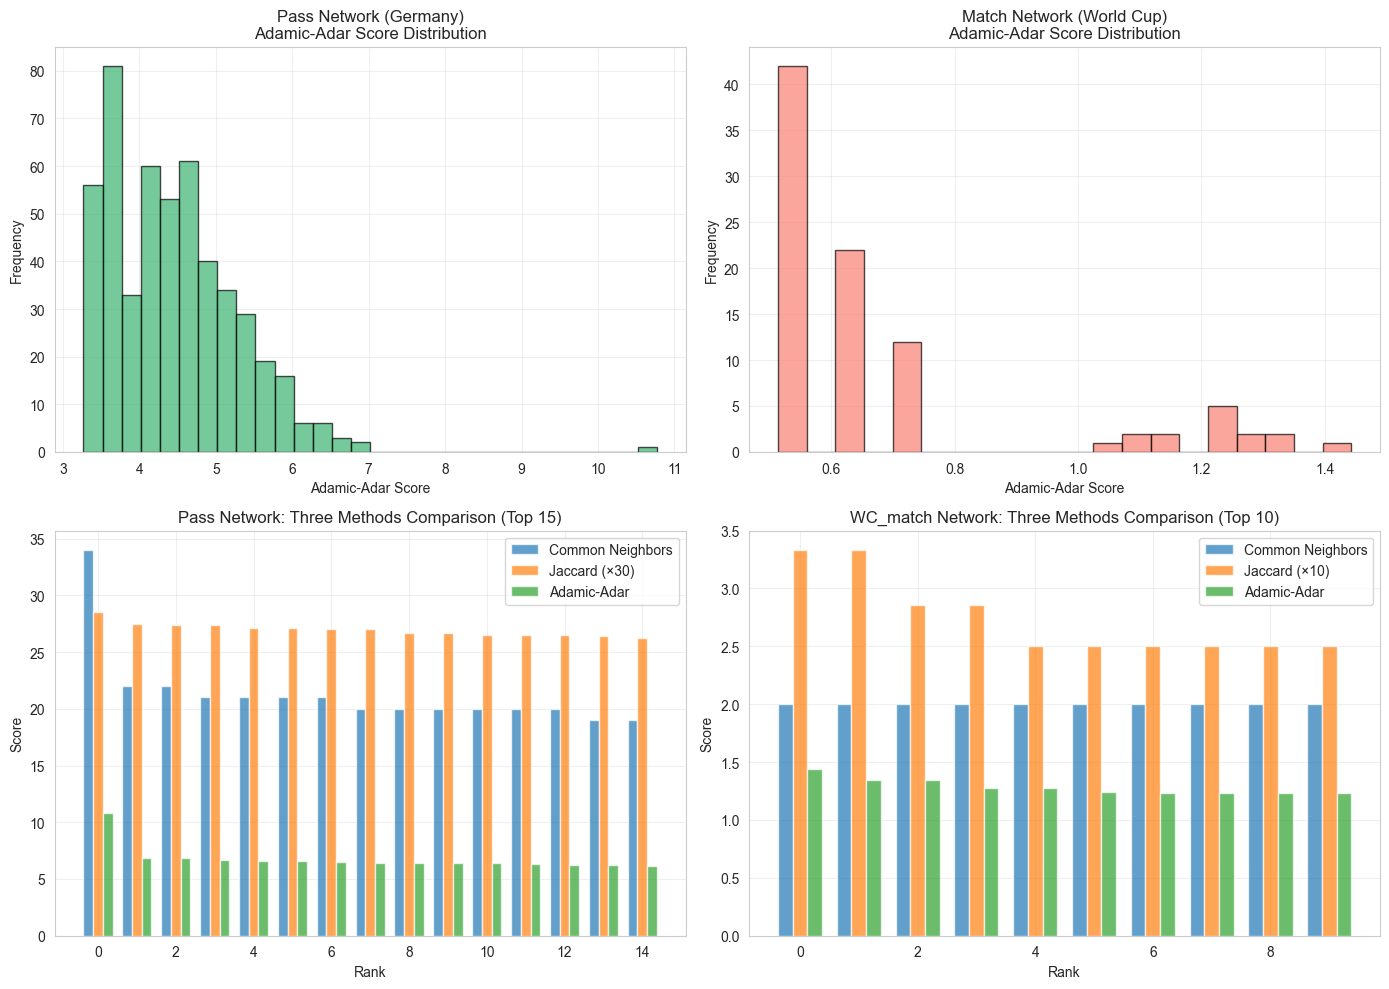


Visualization saved to: c:\Users\jessi\OneDrive\Dokumente\3 FHNW\5. Semester\san\Projekt\san\reports\figures\LE8\adamic_adar_analysis.png


In [18]:
figures_dir = project_root / 'reports' / 'figures' / 'LE8'
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Pass Network - Adamic-Adar Distribution
all_pass_predictions = predict_links_adamic_adar(G_pass, top_k=500)
pass_scores = [score for _, _, score in all_pass_predictions if score > 0]

axes[0, 0].hist(pass_scores, bins=30, edgecolor='black', alpha=0.7, color='mediumseagreen')
axes[0, 0].set_xlabel('Adamic-Adar Score')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Pass Network (Germany)\nAdamic-Adar Score Distribution')
axes[0, 0].grid(True, alpha=0.3)

# 2. Match Network - Adamic-Adar Distribution
all_match_predictions = predict_links_adamic_adar(WC_match, top_k=100)
match_scores = [score for _, _, score in all_match_predictions if score > 0]

axes[0, 1].hist(match_scores, bins=20, edgecolor='black', alpha=0.7, color='salmon')
axes[0, 1].set_xlabel('Adamic-Adar Score')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Match Network (World Cup)\nAdamic-Adar Score Distribution')
axes[0, 1].grid(True, alpha=0.3)

# 3. Pass Network - Three-way comparison (Top 15)
x = np.arange(15)
width = 0.25

cn_scores = [score for _, _, score in predictions_cn[:15]]
jc_scores = [score * 30 for _, _, score in predictions_jc[:15]]  # Scale for visibility
aa_scores = [score for _, _, score in predictions_pass[:15]]

axes[1, 0].bar(x - width, cn_scores, width, label='Common Neighbors', alpha=0.7)
axes[1, 0].bar(x, jc_scores, width, label='Jaccard (×30)', alpha=0.7)
axes[1, 0].bar(x + width, aa_scores, width, label='Adamic-Adar', alpha=0.7)
axes[1, 0].set_xlabel('Rank')
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Pass Network: Three Methods Comparison (Top 15)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Match Network - Three-way comparison (Top 10)
x_wc = np.arange(10)
width_wc = 0.25

cn_scores_wc = [score for _, _, score in predictions_cn_wc[:10]]
jc_scores_wc = [score * 10 for _, _, score in predictions_jc_wc[:10]]  # Scale for visibility
aa_scores_wc = [score for _, _, score in predictions_match[:10]]

axes[1, 1].bar(x_wc - width_wc, cn_scores_wc, width_wc, label='Common Neighbors', alpha=0.7)
axes[1, 1].bar(x_wc, jc_scores_wc, width_wc, label='Jaccard (×10)', alpha=0.7)
axes[1, 1].bar(x_wc + width_wc, aa_scores_wc, width_wc, label='Adamic-Adar', alpha=0.7)
axes[1, 1].set_xlabel('Rank')
axes[1, 1].set_ylabel('Score')
axes[1, 1].set_title('WC_match Network: Three Methods Comparison (Top 10)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(figures_dir / 'adamic_adar_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nVisualization saved to: {figures_dir / 'adamic_adar_analysis.png'}")

## 5. Resource Allocation

**Resource Allocation** models resources flowing from one node to another through common neighbors.

**Football analogy**: Tactical information flows through common teammates, but players with many connections spread their influence thin.

### Mathematical Definition

$$\text{resource\_allocation}(x, y) = \sum_{u \in N(x) \cap N(y)} \frac{1}{|N(u)|}$$

where:
- Each common neighbor $u$ contributes $\frac{1}{\text{degree of } u}$
- No logarithm (stricter penalty than Adamic-Adar)

### Comparison with Adamic-Adar

- **Resource Allocation**: $\frac{1}{k}$ penalty
- **Adamic-Adar**: $\frac{1}{\log(k)}$ penalty
- Resource Allocation penalizes high-degree common neighbors more heavily

### Example

Player A and C share neighbors B (degree 3) and D (degree 3):

$$\text{resource\_allocation}(A, C) = \frac{1}{3} + \frac{1}{3} = \frac{2}{3} \approx 0.67$$

### Interpretation

- Emphasizes rare connections even more than Adamic-Adar
- May give very different rankings than simpler methods
- Can identify non-obvious potential connections

In [19]:
def compute_resource_allocation(G, node1, node2):
    """
    Calculate Resource Allocation score for two nodes.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    node1, node2 : node
        Two nodes that should NOT be directly connected
    
    Returns:
    --------
    float : Resource Allocation score
    """
    neighbors1 = set(G.neighbors(node1))
    neighbors2 = set(G.neighbors(node2))
    common = neighbors1.intersection(neighbors2)
    
    score = 0.0
    for neighbor in common:
        degree = G.degree(neighbor)
        if degree > 0:
            score += 1.0 / degree
    
    return score


def predict_links_resource_allocation(G, top_k=10):
    """
    Predict top-k most likely new edges using Resource Allocation.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph (undirected)
    top_k : int
        Number of predictions to return
    
    Returns:
    --------
    list of tuples: [(node1, node2, score), ...]
        Ranked predictions with their Resource Allocation scores
    """
    predictions = []
    
    # Get all non-connected node pairs
    nodes = list(G.nodes())
    for i, node1 in enumerate(nodes):
        for node2 in nodes[i+1:]:
            # Only consider pairs that are NOT already connected
            if not G.has_edge(node1, node2):
                score = compute_resource_allocation(G, node1, node2)
                if score > 0:  # Only keep pairs with positive score
                    predictions.append((node1, node2, score))
    
    # Sort by score (descending) and return top-k
    predictions.sort(key=lambda x: x[2], reverse=True)
    return predictions[:top_k]

In [20]:
print("=" * 60)
print("RESOURCE ALLOCATION - Pass Network (Germany)")
print("=" * 60)

# Predict potential new passing connections
print("\nPredicting new passing connections (resource flow model)...")
predictions_pass = predict_links_resource_allocation(G_pass, top_k=15)

print(f"\nTop 15 predicted new passing partnerships:")
print(f"{'Rank':<6} {'Player 1':<25} {'Player 2':<25} {'RA Score':<12}")
print("-" * 80)

for rank, (p1, p2, score) in enumerate(predictions_pass, 1):
    player1_name = G_pass.nodes[p1].get('label', p1)
    player2_name = G_pass.nodes[p2].get('label', p2)
    print(f"{rank:<6} {player1_name:<25} {player2_name:<25} {score:.4f}")

RESOURCE ALLOCATION - Pass Network (Germany)

Predicting new passing connections (resource flow model)...

Top 15 predicted new passing partnerships:
Rank   Player 1                  Player 2                  RA Score    
--------------------------------------------------------------------------------
1      M. Gómez                  J. Brekalo                1.4498
2      M. Halstenberg            D. Kaiser                 0.9884
3      O. Wendt                  T. Jantschke              0.9776
4      E. Polanski               D. Geiger                 0.9104
5      R. Koch                   P. Lienhart               0.9021
6      Omar Mascarell            T. Tawatha                0.8763
7      T. Horn                   C. Clemens                0.8752
8      T. Handwerker             J. Córdoba                0.8732
9      A. Mehmedi                T. Jedvaj                 0.8657
10     R. Adler                  R. Zentner                0.8639
11     Raphaël Guerreiro         G. C

In [21]:
print("\n" + "=" * 60)
print("RESOURCE ALLOCATION - Match Network (World Cup)")
print("=" * 60)

print("\nPredicting potential future match-ups (resource flow model)...")
predictions_match = predict_links_resource_allocation(WC_match, top_k=10)

print(f"\nTop 10 predicted future matches:")
print(f"{'Rank':<6} {'Team 1':<20} {'Team 2':<20} {'RA Score':<12}")
print("-" * 60)

for rank, (t1, t2, score) in enumerate(predictions_match, 1):
    team1_name = WC_match.nodes[t1].get('label', t1)
    team2_name = WC_match.nodes[t2].get('label', t2)
    print(f"{rank:<6} {team1_name:<20} {team2_name:<20} {score:.4f}")


RESOURCE ALLOCATION - Match Network (World Cup)

Predicting potential future match-ups (resource flow model)...

Top 10 predicted future matches:
Rank   Team 1               Team 2               RA Score    
------------------------------------------------------------
1      7047                 6380                 0.5000
2      14358                9905                 0.4500
3      15670                1598                 0.4500
4      2413                 12913                0.4167
5      5629                 12430                0.4167
6      6697                 15473                0.4000
7      9598                 8493                 0.3929
8      9598                 15594                0.3929
9      4418                 16823                0.3929
10     4418                 7839                 0.3929


In [22]:
print("\n" + "=" * 60)
print("KEY COMPARISON: Resource Allocation vs Adamic-Adar")
print("=" * 60)

# Get Adamic-Adar predictions
predictions_aa = predict_links_adamic_adar(G_pass, top_k=15)

print("\nDirect comparison of penalty functions:")
print(f"{'Neighbor Degree':<20} {'RA: 1/k':<15} {'AA: 1/log(k)':<15} {'Ratio (AA/RA)':<15}")
print("-" * 65)

test_degrees = [3, 5, 10, 20, 50, 100]
for k in test_degrees:
    ra_weight = 1.0 / k
    aa_weight = 1.0 / np.log(k)
    ratio = aa_weight / ra_weight
    print(f"{k:<20} {ra_weight:.4f}{'':10} {aa_weight:.4f}{'':10} {ratio:.2f}x")

print("\n→ As degree increases, Adamic-Adar penalizes LESS harshly")
print("→ Resource Allocation gives stronger preference to low-degree neighbors")

print("\n\nPass Network - Top 10 Predictions:")
print(f"{'Rank':<6} {'Resource Allocation':<35} {'Adamic-Adar':<35}")
print("-" * 80)

for rank in range(10):
    # Resource Allocation
    p1_ra, p2_ra, score_ra = predictions_pass[rank]
    pair_ra = f"{G_pass.nodes[p1_ra].get('label', p1_ra)[:15]}-{G_pass.nodes[p2_ra].get('label', p2_ra)[:15]}"
    
    # Adamic-Adar
    p1_aa, p2_aa, score_aa = predictions_aa[rank]
    pair_aa = f"{G_pass.nodes[p1_aa].get('label', p1_aa)[:15]}-{G_pass.nodes[p2_aa].get('label', p2_aa)[:15]}"
    
    print(f"{rank+1:<6} {pair_ra:<35} {pair_aa:<35}")


KEY COMPARISON: Resource Allocation vs Adamic-Adar

Direct comparison of penalty functions:
Neighbor Degree      RA: 1/k         AA: 1/log(k)    Ratio (AA/RA)  
-----------------------------------------------------------------
3                    0.3333           0.9102           2.73x
5                    0.2000           0.6213           3.11x
10                   0.1000           0.4343           4.34x
20                   0.0500           0.3338           6.68x
50                   0.0200           0.2556           12.78x
100                  0.0100           0.2171           21.71x

→ As degree increases, Adamic-Adar penalizes LESS harshly
→ Resource Allocation gives stronger preference to low-degree neighbors


Pass Network - Top 10 Predictions:
Rank   Resource Allocation                 Adamic-Adar                        
--------------------------------------------------------------------------------
1      M. Gómez-J. Brekalo                 M. Gómez-J. Brekalo              

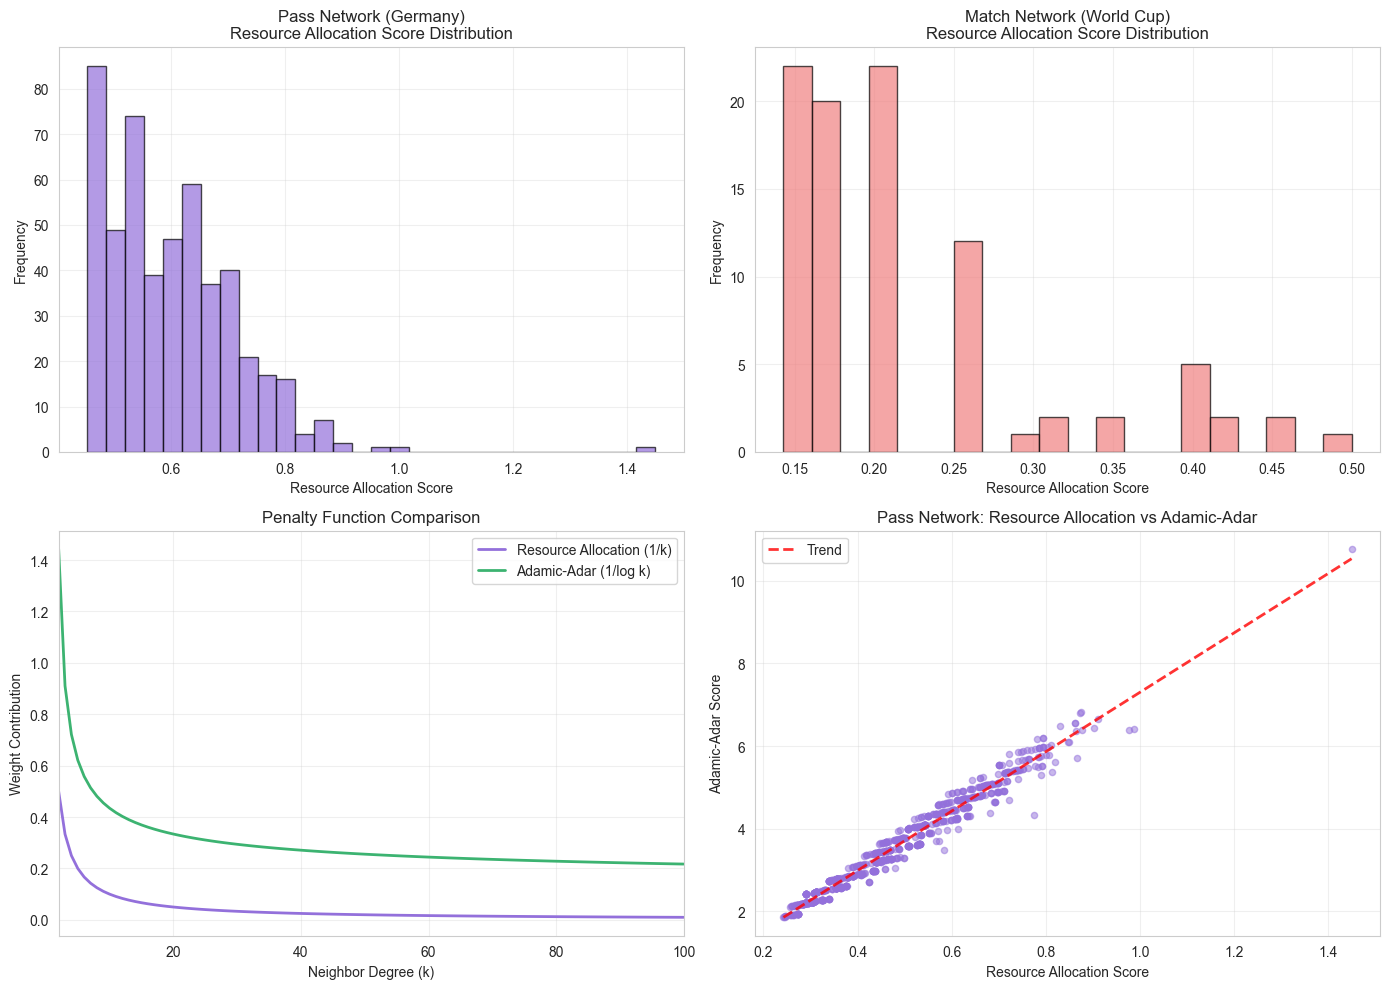


Visualization saved to: c:\Users\jessi\OneDrive\Dokumente\3 FHNW\5. Semester\san\Projekt\san\reports\figures\LE8\resource_allocation_analysis.png


In [23]:
figures_dir = project_root / 'reports' / 'figures' / 'LE8'
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Pass Network - Resource Allocation Distribution
all_pass_predictions = predict_links_resource_allocation(G_pass, top_k=500)
pass_scores = [score for _, _, score in all_pass_predictions if score > 0]

axes[0, 0].hist(pass_scores, bins=30, edgecolor='black', alpha=0.7, color='mediumpurple')
axes[0, 0].set_xlabel('Resource Allocation Score')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Pass Network (Germany)\nResource Allocation Score Distribution')
axes[0, 0].grid(True, alpha=0.3)

# 2. Match Network - Resource Allocation Distribution
all_match_predictions = predict_links_resource_allocation(WC_match, top_k=100)
match_scores = [score for _, _, score in all_match_predictions if score > 0]

axes[0, 1].hist(match_scores, bins=20, edgecolor='black', alpha=0.7, color='lightcoral')
axes[0, 1].set_xlabel('Resource Allocation Score')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Match Network (World Cup)\nResource Allocation Score Distribution')
axes[0, 1].grid(True, alpha=0.3)

# 3. Penalty Function Comparison
degrees = np.arange(2, 101)
ra_penalties = 1.0 / degrees
aa_penalties = 1.0 / np.log(degrees)

axes[1, 0].plot(degrees, ra_penalties, label='Resource Allocation (1/k)', linewidth=2, color='mediumpurple')
axes[1, 0].plot(degrees, aa_penalties, label='Adamic-Adar (1/log k)', linewidth=2, color='mediumseagreen')
axes[1, 0].set_xlabel('Neighbor Degree (k)')
axes[1, 0].set_ylabel('Weight Contribution')
axes[1, 0].set_title('Penalty Function Comparison')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xlim(2, 100)

# 4. Resource Allocation vs Adamic-Adar scatter
# Get scores for same pairs
all_pairs_pass = predict_links_resource_allocation(G_pass, top_k=1000)
aa_scores_map = {}
for p1, p2, score in predict_links_adamic_adar(G_pass, top_k=1000):
    aa_scores_map[(p1, p2)] = score

ra_vals = []
aa_vals = []
for p1, p2, ra_score in all_pairs_pass:
    if (p1, p2) in aa_scores_map:
        ra_vals.append(ra_score)
        aa_vals.append(aa_scores_map[(p1, p2)])

axes[1, 1].scatter(ra_vals, aa_vals, alpha=0.5, s=20, color='mediumpurple')
axes[1, 1].set_xlabel('Resource Allocation Score')
axes[1, 1].set_ylabel('Adamic-Adar Score')
axes[1, 1].set_title('Pass Network: Resource Allocation vs Adamic-Adar')
axes[1, 1].grid(True, alpha=0.3)

# Add trend line
z = np.polyfit(ra_vals, aa_vals, 1)
p = np.poly1d(z)
axes[1, 1].plot(sorted(ra_vals), p(sorted(ra_vals)), "r--", alpha=0.8, linewidth=2, label='Trend')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(figures_dir / 'resource_allocation_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nVisualization saved to: {figures_dir / 'resource_allocation_analysis.png'}")



## 6. Preferential Attachment

**Preferential Attachment** is based on the "rich get richer" phenomenon: popular nodes attract more connections.

### Intuition

Nodes with many existing connections are more likely to form new connections, regardless of network structure or common neighbors.

**Football examples**:
- Star players (high degree) naturally develop more passing connections
- Popular teams play more matches across competitions

### Mathematical Definition

$$\text{preferential\_attachment}(x, y) = |N(x)| \times |N(y)|$$

Simply the product of the degrees of both nodes.

### Theoretical Background

Based on the **Barabási-Albert model** of scale-free networks, where connection probability is proportional to node degree.

### Example

Player A has 3 neighbors, Player C has 3 neighbors:

$$\text{preferential\_attachment}(A, C) = 3 \times 3 = 9$$

Player A has 3 neighbors, Player G has 4 neighbors:

$$\text{preferential\_attachment}(A, G) = 3 \times 4 = 12$$

In [24]:
def compute_preferential_attachment(G, node1, node2):
    """
    Calculate Preferential Attachment score for two nodes.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    node1, node2 : node
        Two nodes (can be connected or not)
    
    Returns:
    --------
    int : Product of degrees
    """
    degree1 = G.degree(node1)
    degree2 = G.degree(node2)
    
    return degree1 * degree2


def predict_links_preferential_attachment(G, top_k=10):
    """
    Predict top-k most likely new edges using Preferential Attachment.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph (undirected)
    top_k : int
        Number of predictions to return
    
    Returns:
    --------
    list of tuples: [(node1, node2, score), ...]
        Ranked predictions with their PA scores
    """
    predictions = []
    
    # Get all non-connected node pairs
    nodes = list(G.nodes())
    for i, node1 in enumerate(nodes):
        for node2 in nodes[i+1:]:
            # Only consider pairs that are NOT already connected
            if not G.has_edge(node1, node2):
                score = compute_preferential_attachment(G, node1, node2)
                if score > 0:  # Only keep pairs with positive score
                    predictions.append((node1, node2, score))
    
    # Sort by score (descending) and return top-k
    predictions.sort(key=lambda x: x[2], reverse=True)
    return predictions[:top_k]

In [25]:
print("=" * 60)
print("PREFERENTIAL ATTACHMENT - Pass Network (Germany)")
print("=" * 60)

# Predict potential new passing connections
print("\nPredicting new passing connections (popularity-based)...")
predictions_pass = predict_links_preferential_attachment(G_pass, top_k=15)

print(f"\nTop 15 predicted new passing partnerships:")
print(f"{'Rank':<6} {'Player 1':<25} {'Player 2':<25} {'PA Score':<10} {'Deg(P1)':<10} {'Deg(P2)':<10}")
print("-" * 95)

for rank, (p1, p2, score) in enumerate(predictions_pass, 1):
    player1_name = G_pass.nodes[p1].get('label', p1)
    player2_name = G_pass.nodes[p2].get('label', p2)
    deg1 = G_pass.degree(p1)
    deg2 = G_pass.degree(p2)
    print(f"{rank:<6} {player1_name:<25} {player2_name:<25} {score:<10} {deg1:<10} {deg2:<10}")

PREFERENTIAL ATTACHMENT - Pass Network (Germany)

Predicting new passing connections (popularity-based)...

Top 15 predicted new passing partnerships:
Rank   Player 1                  Player 2                  PA Score   Deg(P1)    Deg(P2)   
-----------------------------------------------------------------------------------------------
1      S. Wagner                 J. Brekalo                2068       47         44        
2      S. Wagner                 S. Terodde                2021       47         43        
3      J. Brekalo                J. Toljan                 1848       44         42        
4      S. Terodde                J. Toljan                 1806       43         42        
5      M. Gómez                  S. Wagner                 1786       38         47        
6      S. Wagner                 A. Mehmedi                1739       47         37        
7      S. Wagner                 S. Langkamp               1692       47         36        
8      M. Gómez  

In [26]:
print("\n" + "=" * 60)
print("PREFERENTIAL ATTACHMENT - Match Network (World Cup)")
print("=" * 60)

print("\nPredicting potential future match-ups (popularity-based)...")
predictions_match = predict_links_preferential_attachment(WC_match, top_k=10)

print(f"\nTop 10 predicted future matches:")
print(f"{'Rank':<6} {'Team 1':<20} {'Team 2':<20} {'PA Score':<10} {'Deg(T1)':<10} {'Deg(T2)':<10}")
print("-" * 80)

for rank, (t1, t2, score) in enumerate(predictions_match, 1):
    team1_name = WC_match.nodes[t1].get('label', t1)
    team2_name = WC_match.nodes[t2].get('label', t2)
    deg1 = WC_match.degree(t1)
    deg2 = WC_match.degree(t2)
    print(f"{rank:<6} {team1_name:<20} {team2_name:<20} {score:<10} {deg1:<10} {deg2:<10}")




PREFERENTIAL ATTACHMENT - Match Network (World Cup)

Predicting potential future match-ups (popularity-based)...

Top 10 predicted future matches:
Rank   Team 1               Team 2               PA Score   Deg(T1)    Deg(T2)   
--------------------------------------------------------------------------------
1      9598                 5629                 42         7          6         
2      4418                 2413                 42         7          6         
3      9598                 7047                 35         7          5         
4      9598                 6380                 35         7          5         
5      9598                 15670                35         7          5         
6      4418                 14358                35         7          5         
7      4418                 7047                 35         7          5         
8      4418                 6380                 35         7          5         
9      2413                 14358

In [27]:
print("\n" + "=" * 60)
print("COMPARISON: Preferential Attachment vs Other Methods")
print("=" * 60)

# Get predictions from all methods for Pass Network
predictions_cn = predict_links_common_neighbors(G_pass, top_k=15)
predictions_jc = predict_links_jaccard(G_pass, top_k=15)
predictions_aa = predict_links_adamic_adar(G_pass, top_k=15)
predictions_ra = predict_links_resource_allocation(G_pass, top_k=15)

print("\nPass Network - Top 5 Predictions Comparison:")
print(f"{'Rank':<6} {'Pref. Attach.':<30} {'Common Nbrs':<30} {'Jaccard':<30}")
print("-" * 100)

for rank in range(5):
    # Preferential Attachment
    p1_pa, p2_pa, score_pa = predictions_pass[rank]
    pair_pa = f"{G_pass.nodes[p1_pa].get('label', p1_pa)[:12]}-{G_pass.nodes[p2_pa].get('label', p2_pa)[:12]}"
    
    # Common Neighbors
    p1_cn, p2_cn, score_cn = predictions_cn[rank]
    pair_cn = f"{G_pass.nodes[p1_cn].get('label', p1_cn)[:12]}-{G_pass.nodes[p2_cn].get('label', p2_cn)[:12]}"
    
    # Jaccard
    p1_jc, p2_jc, score_jc = predictions_jc[rank]
    pair_jc = f"{G_pass.nodes[p1_jc].get('label', p1_jc)[:12]}-{G_pass.nodes[p2_jc].get('label', p2_jc)[:12]}"
    
    print(f"{rank+1:<6} {pair_pa:<30} {pair_cn:<30} {pair_jc:<30}")

# Get predictions from all methods for Match Network
predictions_cn_wc = predict_links_common_neighbors(WC_match, top_k=10)
predictions_jc_wc = predict_links_jaccard(WC_match, top_k=10)
predictions_aa_wc = predict_links_adamic_adar(WC_match, top_k=10)
predictions_ra_wc = predict_links_resource_allocation(WC_match, top_k=10)

print("\n\nWC_match Network - Top 5 Predictions Comparison:")
print(f"{'Rank':<6} {'Pref. Attach.':<30} {'Common Nbrs':<30} {'Jaccard':<30}")
print("-" * 100)

for rank in range(5):
    # Preferential Attachment
    t1_pa, t2_pa, score_pa = predictions_match[rank]
    pair_pa = f"{WC_match.nodes[t1_pa].get('label', t1_pa)[:12]}-{WC_match.nodes[t2_pa].get('label', t2_pa)[:12]}"
    
    # Common Neighbors
    t1_cn, t2_cn, score_cn = predictions_cn_wc[rank]
    pair_cn = f"{WC_match.nodes[t1_cn].get('label', t1_cn)[:12]}-{WC_match.nodes[t2_cn].get('label', t2_cn)[:12]}"
    
    # Jaccard
    t1_jc, t2_jc, score_jc = predictions_jc_wc[rank]
    pair_jc = f"{WC_match.nodes[t1_jc].get('label', t1_jc)[:12]}-{WC_match.nodes[t2_jc].get('label', t2_jc)[:12]}"
    
    print(f"{rank+1:<6} {pair_pa:<30} {pair_cn:<30} {pair_jc:<30}")

print("\n→ Rankings often COMPLETELY DIFFERENT from neighborhood methods")
print("→ PA captures different aspect: popularity rather than structural similarity")


COMPARISON: Preferential Attachment vs Other Methods

Pass Network - Top 5 Predictions Comparison:
Rank   Pref. Attach.                  Common Nbrs                    Jaccard                       
----------------------------------------------------------------------------------------------------
1      S. Wagner-J. Brekalo           M. Gómez-J. Brekalo            R. Adler-R. Zentner           
2      S. Wagner-S. Terodde           T. Handwerke-J. Córdoba        T. Handwerke-J. Córdoba       
3      J. Brekalo-J. Toljan           T. Horn-C. Clemens             Raphaël Guer-G. Castro        
4      S. Terodde-J. Toljan           Raphaël Guer-G. Castro         E. Polanski-D. Geiger         
5      M. Gómez-S. Wagner             Raphaël Guer-M. Philipp        M. Halstenbe-D. Kaiser        


WC_match Network - Top 5 Predictions Comparison:
Rank   Pref. Attach.                  Common Nbrs                    Jaccard                       
------------------------------------------------

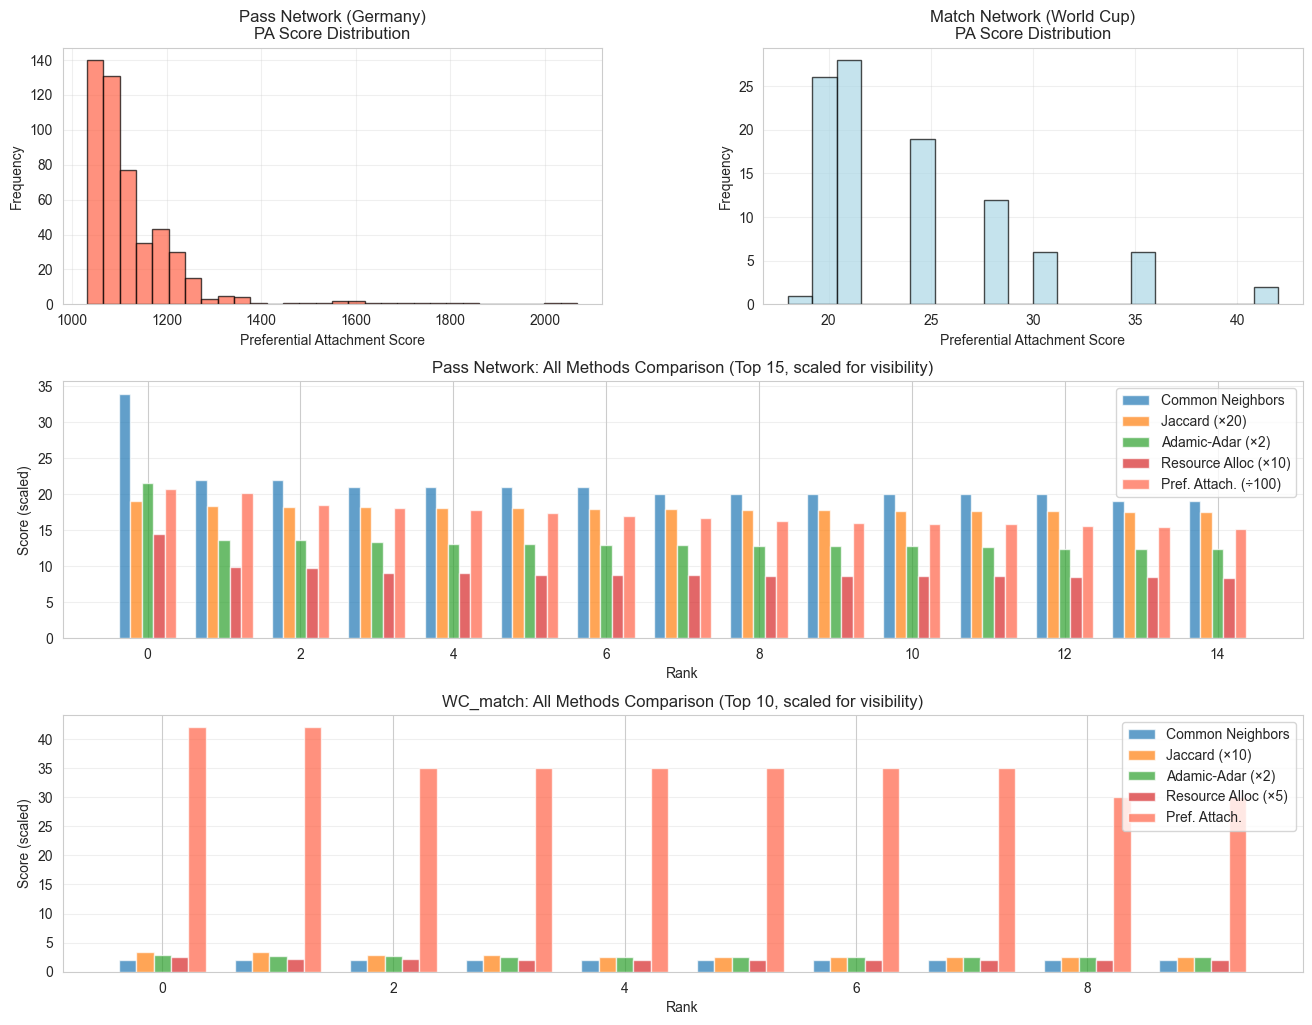


Visualization saved to: c:\Users\jessi\OneDrive\Dokumente\3 FHNW\5. Semester\san\Projekt\san\reports\figures\LE8\preferential_attachment_analysis.png


In [28]:
figures_dir = project_root / 'reports' / 'figures' / 'LE8'
figures_dir.mkdir(parents=True, exist_ok=True)

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# 1. Pass Network - PA Distribution
ax1 = fig.add_subplot(gs[0, 0])
all_pass_predictions = predict_links_preferential_attachment(G_pass, top_k=500)
pass_scores = [score for _, _, score in all_pass_predictions if score > 0]

ax1.hist(pass_scores, bins=30, edgecolor='black', alpha=0.7, color='tomato')
ax1.set_xlabel('Preferential Attachment Score')
ax1.set_ylabel('Frequency')
ax1.set_title('Pass Network (Germany)\nPA Score Distribution')
ax1.grid(True, alpha=0.3)

# 2. Match Network - PA Distribution
ax2 = fig.add_subplot(gs[0, 1])
all_match_predictions = predict_links_preferential_attachment(WC_match, top_k=100)
match_scores = [score for _, _, score in all_match_predictions if score > 0]

ax2.hist(match_scores, bins=20, edgecolor='black', alpha=0.7, color='lightblue')
ax2.set_xlabel('Preferential Attachment Score')
ax2.set_ylabel('Frequency')
ax2.set_title('Match Network (World Cup)\nPA Score Distribution')
ax2.grid(True, alpha=0.3)

# 3. Pass Network - Five-method comparison (Top 15)
ax3 = fig.add_subplot(gs[1, :])
x = np.arange(15)
width = 0.15

cn_scores = [score for _, _, score in predictions_cn[:15]]
jc_scores = [score * 20 for _, _, score in predictions_jc[:15]]  # Scale for visibility
aa_scores = [score * 2 for _, _, score in predictions_aa[:15]]  # Scale for visibility
ra_scores = [score * 10 for _, _, score in predictions_ra[:15]]  # Scale for visibility
pa_scores = [score / 100 for _, _, score in predictions_pass[:15]]  # Scale down for visibility

ax3.bar(x - 2*width, cn_scores, width, label='Common Neighbors', alpha=0.7)
ax3.bar(x - width, jc_scores, width, label='Jaccard (×20)', alpha=0.7)
ax3.bar(x, aa_scores, width, label='Adamic-Adar (×2)', alpha=0.7)
ax3.bar(x + width, ra_scores, width, label='Resource Alloc (×10)', alpha=0.7)
ax3.bar(x + 2*width, pa_scores, width, label='Pref. Attach. (÷100)', alpha=0.7, color='tomato')
ax3.set_xlabel('Rank')
ax3.set_ylabel('Score (scaled)')
ax3.set_title('Pass Network: All Methods Comparison (Top 15, scaled for visibility)')
ax3.legend(loc='upper right')
ax3.grid(True, alpha=0.3, axis='y')

# 4. Match Network - Five-method comparison (Top 10)
ax4 = fig.add_subplot(gs[2, :])
x_wc = np.arange(10)
width_wc = 0.15

cn_scores_wc = [score for _, _, score in predictions_cn_wc[:10]]
jc_scores_wc = [score * 10 for _, _, score in predictions_jc_wc[:10]]  # Scale for visibility
aa_scores_wc = [score * 2 for _, _, score in predictions_aa_wc[:10]]  # Scale for visibility
ra_scores_wc = [score * 5 for _, _, score in predictions_ra_wc[:10]]  # Scale for visibility
pa_scores_wc = [score for _, _, score in predictions_match[:10]]  # Scale down for visibility

ax4.bar(x_wc - 2*width_wc, cn_scores_wc, width_wc, label='Common Neighbors', alpha=0.7)
ax4.bar(x_wc - width_wc, jc_scores_wc, width_wc, label='Jaccard (×10)', alpha=0.7)
ax4.bar(x_wc, aa_scores_wc, width_wc, label='Adamic-Adar (×2)', alpha=0.7)
ax4.bar(x_wc + width_wc, ra_scores_wc, width_wc, label='Resource Alloc (×5)', alpha=0.7)
ax4.bar(x_wc + 2*width_wc, pa_scores_wc, width_wc, label='Pref. Attach.', alpha=0.7, color='tomato')
ax4.set_xlabel('Rank')
ax4.set_ylabel('Score (scaled)')
ax4.set_title('WC_match: All Methods Comparison (Top 10, scaled for visibility)')
ax4.legend(loc='upper right')
ax4.grid(True, alpha=0.3, axis='y')

plt.savefig(figures_dir / 'preferential_attachment_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nVisualization saved to: {figures_dir / 'preferential_attachment_analysis.png'}")

## 7. Comparing Algorithms

### Different Perspectives on Link Prediction

Each algorithm captures different mechanisms:

1. **Common Neighbors**: Triadic closure, local clustering
2. **Jaccard Coefficient**: Relative similarity in neighborhoods
3. **Adamic-Adar**: Valuable rare connections
4. **Resource Allocation**: Information/resource flow
5. **Preferential Attachment**: Popularity and growth dynamics

In [34]:
print("\nCollecting predictions from all algorithms...")

# Get top predictions from each algorithm
k = 100  # Get more predictions for better analysis

predictions_cn = predict_links_common_neighbors(G_pass, top_k=k)
predictions_jc = predict_links_jaccard(G_pass, top_k=k)
predictions_aa = predict_links_adamic_adar(G_pass, top_k=k)
predictions_ra = predict_links_resource_allocation(G_pass, top_k=k)
predictions_pa = predict_links_preferential_attachment(G_pass, top_k=k)

predictions_cn_wc = predict_links_common_neighbors(WC_match, top_k=k)
predictions_jc_wc = predict_links_jaccard(WC_match, top_k=k)
predictions_aa_wc = predict_links_adamic_adar(WC_match, top_k=k)
predictions_ra_wc = predict_links_resource_allocation(WC_match, top_k=k)
predictions_pa_wc = predict_links_preferential_attachment(WC_match, top_k=k)

print(f"Collected top {k} predictions from each algorithm")


Collected top 100 predictions from each algorithm


In [36]:
print("\n" + "=" * 70)
print("PREDICTION OVERLAP ANALYSIS")
print("=" * 70)

def get_top_pairs(predictions, n=20):
    """Get set of top n predicted pairs"""
    return {(p1, p2) for p1, p2, _ in predictions[:n]}

algo_names = ['Common Neighbors', 'Jaccard', 'Adamic-Adar', 'Resource Alloc', 'Pref. Attach']

print("PASS NETWORK - Overlap Analysis")

# Get top 20 predictions from each algorithm
top_20_cn = get_top_pairs(predictions_cn, 20)
top_20_jc = get_top_pairs(predictions_jc, 20)
top_20_aa = get_top_pairs(predictions_aa, 20)
top_20_ra = get_top_pairs(predictions_ra, 20)
top_20_pa = get_top_pairs(predictions_pa, 20)

algo_sets_pass = [top_20_cn, top_20_jc, top_20_aa, top_20_ra, top_20_pa]

print("\nOverlap in Top 20 Predictions (Jaccard similarity):")
print(f"{'Algorithm Pair':<40} {'Overlap':<10} {'Jaccard Similarity':<20}")
print("-" * 70)

overlap_matrix_pass = np.zeros((5, 5))

for i in range(5):
    for j in range(i+1, 5):
        overlap = len(algo_sets_pass[i].intersection(algo_sets_pass[j]))
        union = len(algo_sets_pass[i].union(algo_sets_pass[j]))
        jaccard = overlap / union if union > 0 else 0
        overlap_matrix_pass[i, j] = jaccard
        overlap_matrix_pass[j, i] = jaccard
        
        pair_name = f"{algo_names[i]} ↔ {algo_names[j]}"
        print(f"{pair_name:<40} {overlap:<10} {jaccard:.3f}")

np.fill_diagonal(overlap_matrix_pass, 1.0)

print("\nMATCH NETWORK - Overlap Analysis")

# Get top 20 predictions from each algorithm (or fewer if network is smaller)
top_20_cn_wc = get_top_pairs(predictions_cn_wc, 20)
top_20_jc_wc = get_top_pairs(predictions_jc_wc, 20)
top_20_aa_wc = get_top_pairs(predictions_aa_wc, 20)
top_20_ra_wc = get_top_pairs(predictions_ra_wc, 20)
top_20_pa_wc = get_top_pairs(predictions_pa_wc, 20)

algo_sets_wc = [top_20_cn_wc, top_20_jc_wc, top_20_aa_wc, top_20_ra_wc, top_20_pa_wc]

print("\nOverlap in Top 20 Predictions (Jaccard similarity):")
print(f"{'Algorithm Pair':<40} {'Overlap':<10} {'Jaccard Similarity':<20}")
print("-" * 70)

overlap_matrix_wc = np.zeros((5, 5))

for i in range(5):
    for j in range(i+1, 5):
        overlap = len(algo_sets_wc[i].intersection(algo_sets_wc[j]))
        union = len(algo_sets_wc[i].union(algo_sets_wc[j]))
        jaccard = overlap / union if union > 0 else 0
        overlap_matrix_wc[i, j] = jaccard
        overlap_matrix_wc[j, i] = jaccard
        
        pair_name = f"{algo_names[i]} ↔ {algo_names[j]}"
        print(f"{pair_name:<40} {overlap:<10} {jaccard:.3f}")

np.fill_diagonal(overlap_matrix_wc, 1.0)

print("\n" + "="*70)
print("SUMMARY")
print("="*70)
print("- High overlap: Algorithms capture similar patterns")
print("- Low overlap: Algorithms capture different aspects")
print("- Pass network typically shows higher overlap than match network")


PREDICTION OVERLAP ANALYSIS
PASS NETWORK - Overlap Analysis

Overlap in Top 20 Predictions (Jaccard similarity):
Algorithm Pair                           Overlap    Jaccard Similarity  
----------------------------------------------------------------------
Common Neighbors ↔ Jaccard               9          0.290
Common Neighbors ↔ Adamic-Adar           16         0.667
Common Neighbors ↔ Resource Alloc        12         0.429
Common Neighbors ↔ Pref. Attach          1          0.026
Jaccard ↔ Adamic-Adar                    11         0.379
Jaccard ↔ Resource Alloc                 13         0.481
Jaccard ↔ Pref. Attach                   0          0.000
Adamic-Adar ↔ Resource Alloc             16         0.667
Adamic-Adar ↔ Pref. Attach               1          0.026
Resource Alloc ↔ Pref. Attach            1          0.026

MATCH NETWORK - Overlap Analysis

Overlap in Top 20 Predictions (Jaccard similarity):
Algorithm Pair                           Overlap    Jaccard Similarity  
--

In [39]:
from scipy.stats import spearmanr

# Helper function to get score
def get_score(method, pair, G, score_maps):
    """Get score for a pair, calculating if not in predictions"""
    if pair in score_maps[method]:
        return score_maps[method][pair]
    
    p1, p2 = pair
    # Calculate score based on method
    if method == 'CN':
        return compute_common_neighbors(G, p1, p2)
    elif method == 'JC':
        return compute_jaccard_coefficient(G, p1, p2)
    elif method == 'AA':
        return compute_adamic_adar(G, p1, p2)
    elif method == 'RA':
        return compute_resource_allocation(G, p1, p2)
    elif method == 'PA':
        return compute_preferential_attachment(G, p1, p2)
    return 0

print("\nPASS NETWORK - Rank Correlation")
print("="*70)

# Create score maps for pass network
score_maps_pass = {
    'CN': {(p1, p2): score for p1, p2, score in predictions_cn},
    'JC': {(p1, p2): score for p1, p2, score in predictions_jc},
    'AA': {(p1, p2): score for p1, p2, score in predictions_aa},
    'RA': {(p1, p2): score for p1, p2, score in predictions_ra},
    'PA': {(p1, p2): score for p1, p2, score in predictions_pa}
}

# Get union of all predicted pairs
all_pairs_union_pass = set()
for method_pairs in score_maps_pass.values():
    all_pairs_union_pass.update(method_pairs.keys())

# Get pairs that appear in at least 3 methods
pair_counts_pass = {}
for pair in all_pairs_union_pass:
    count = sum(1 for method_pairs in score_maps_pass.values() if pair in method_pairs)
    pair_counts_pass[pair] = count

common_pairs_pass = [pair for pair, count in pair_counts_pass.items() if count >= 3][:500]

print(f"Analyzing {len(common_pairs_pass)} pairs (appearing in ≥3 methods)...")

print(f"\nSpearman Rank Correlations:")
print(f"{'Algorithm Pair':<40} {'Correlation':<15}")
print("-" * 55)

correlation_matrix_pass = np.eye(5)

for i, method1 in enumerate(['CN', 'JC', 'AA', 'RA', 'PA']):
    for j, method2 in enumerate(['CN', 'JC', 'AA', 'RA', 'PA']):
        if i < j:
            scores1 = [get_score(method1, pair, G_pass, score_maps_pass) for pair in common_pairs_pass]
            scores2 = [get_score(method2, pair, G_pass, score_maps_pass) for pair in common_pairs_pass]
            
            if len(scores1) > 0 and len(scores2) > 0:
                corr, _ = spearmanr(scores1, scores2)
                correlation_matrix_pass[i, j] = corr
                correlation_matrix_pass[j, i] = corr
                
                pair_name = f"{algo_names[i]} ↔ {algo_names[j]}"
                print(f"{pair_name:<40} {corr:.3f}")


print("\nMATCH NETWORK - Rank Correlation")
print("="*70)

# Create score maps for match network
score_maps_wc = {
    'CN': {(p1, p2): score for p1, p2, score in predictions_cn_wc},
    'JC': {(p1, p2): score for p1, p2, score in predictions_jc_wc},
    'AA': {(p1, p2): score for p1, p2, score in predictions_aa_wc},
    'RA': {(p1, p2): score for p1, p2, score in predictions_ra_wc},
    'PA': {(p1, p2): score for p1, p2, score in predictions_pa_wc}
}

# Get union of all predicted pairs
all_pairs_union_wc = set()
for method_pairs in score_maps_wc.values():
    all_pairs_union_wc.update(method_pairs.keys())

# Get pairs that appear in at least 3 methods
pair_counts_wc = {}
for pair in all_pairs_union_wc:
    count = sum(1 for method_pairs in score_maps_wc.values() if pair in method_pairs)
    pair_counts_wc[pair] = count

common_pairs_wc = [pair for pair, count in pair_counts_wc.items() if count >= 3][:500]

print(f"Analyzing {len(common_pairs_wc)} pairs (appearing in ≥3 methods)...")

print(f"\nSpearman Rank Correlations:")
print(f"{'Algorithm Pair':<40} {'Correlation':<15}")
print("-" * 55)

correlation_matrix_wc = np.eye(5)

for i, method1 in enumerate(['CN', 'JC', 'AA', 'RA', 'PA']):
    for j, method2 in enumerate(['CN', 'JC', 'AA', 'RA', 'PA']):
        if i < j:
            scores1 = [get_score(method1, pair, WC_match, score_maps_wc) for pair in common_pairs_wc]
            scores2 = [get_score(method2, pair, WC_match, score_maps_wc) for pair in common_pairs_wc]
            
            if len(scores1) > 0 and len(scores2) > 0:
                corr, _ = spearmanr(scores1, scores2)
                correlation_matrix_wc[i, j] = corr
                correlation_matrix_wc[j, i] = corr
                
                pair_name = f"{algo_names[i]} ↔ {algo_names[j]}"
                print(f"{pair_name:<40} {corr:.3f}")


print("\nSUMMARY")
print("="*70)
print("- High correlation (>0.7): Similar ranking of candidates")
print("- Medium correlation (0.3-0.7): Some similarity in rankings")
print("- Low correlation (<0.3): Different ranking priorities")


PASS NETWORK - Rank Correlation
Analyzing 92 pairs (appearing in ≥3 methods)...

Spearman Rank Correlations:
Algorithm Pair                           Correlation    
-------------------------------------------------------
Common Neighbors ↔ Jaccard               0.328
Common Neighbors ↔ Adamic-Adar           0.955
Common Neighbors ↔ Resource Alloc        0.656
Common Neighbors ↔ Pref. Attach          0.575
Jaccard ↔ Adamic-Adar                    0.359
Jaccard ↔ Resource Alloc                 0.380
Jaccard ↔ Pref. Attach                   -0.425
Adamic-Adar ↔ Resource Alloc             0.825
Adamic-Adar ↔ Pref. Attach               0.525
Resource Alloc ↔ Pref. Attach            0.307

MATCH NETWORK - Rank Correlation
Analyzing 91 pairs (appearing in ≥3 methods)...

Spearman Rank Correlations:
Algorithm Pair                           Correlation    
-------------------------------------------------------
Common Neighbors ↔ Jaccard               0.651
Common Neighbors ↔ Adamic-Adar     

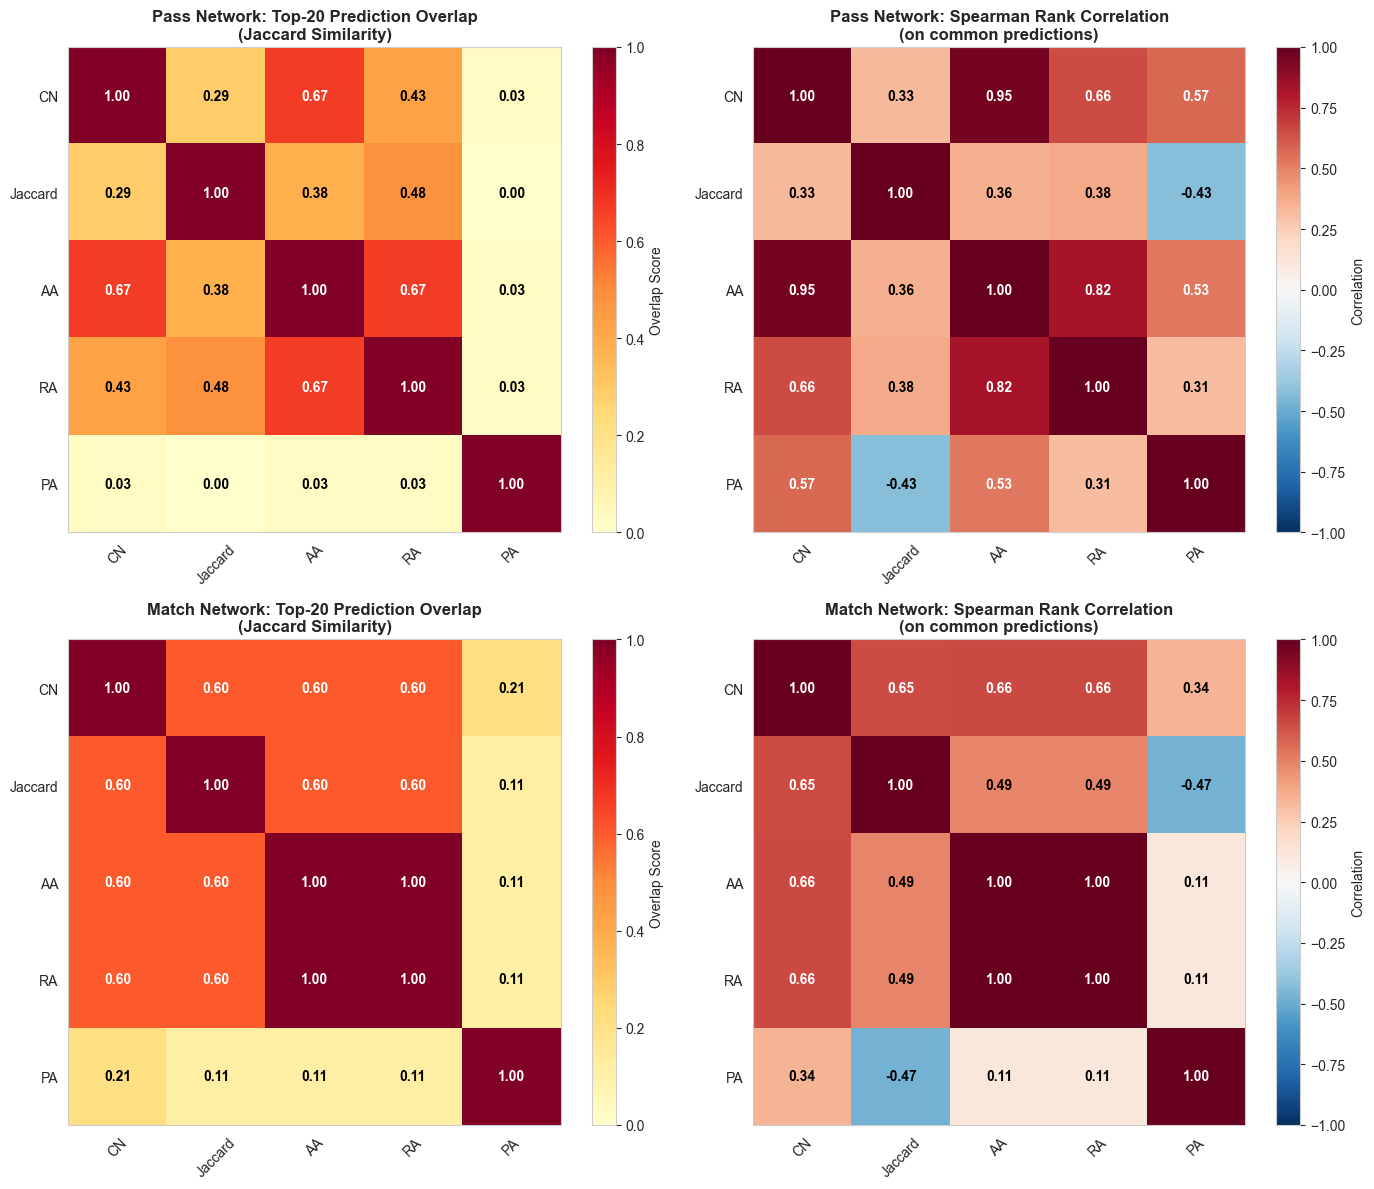

Saved: algorithm_overlap_correlation.png


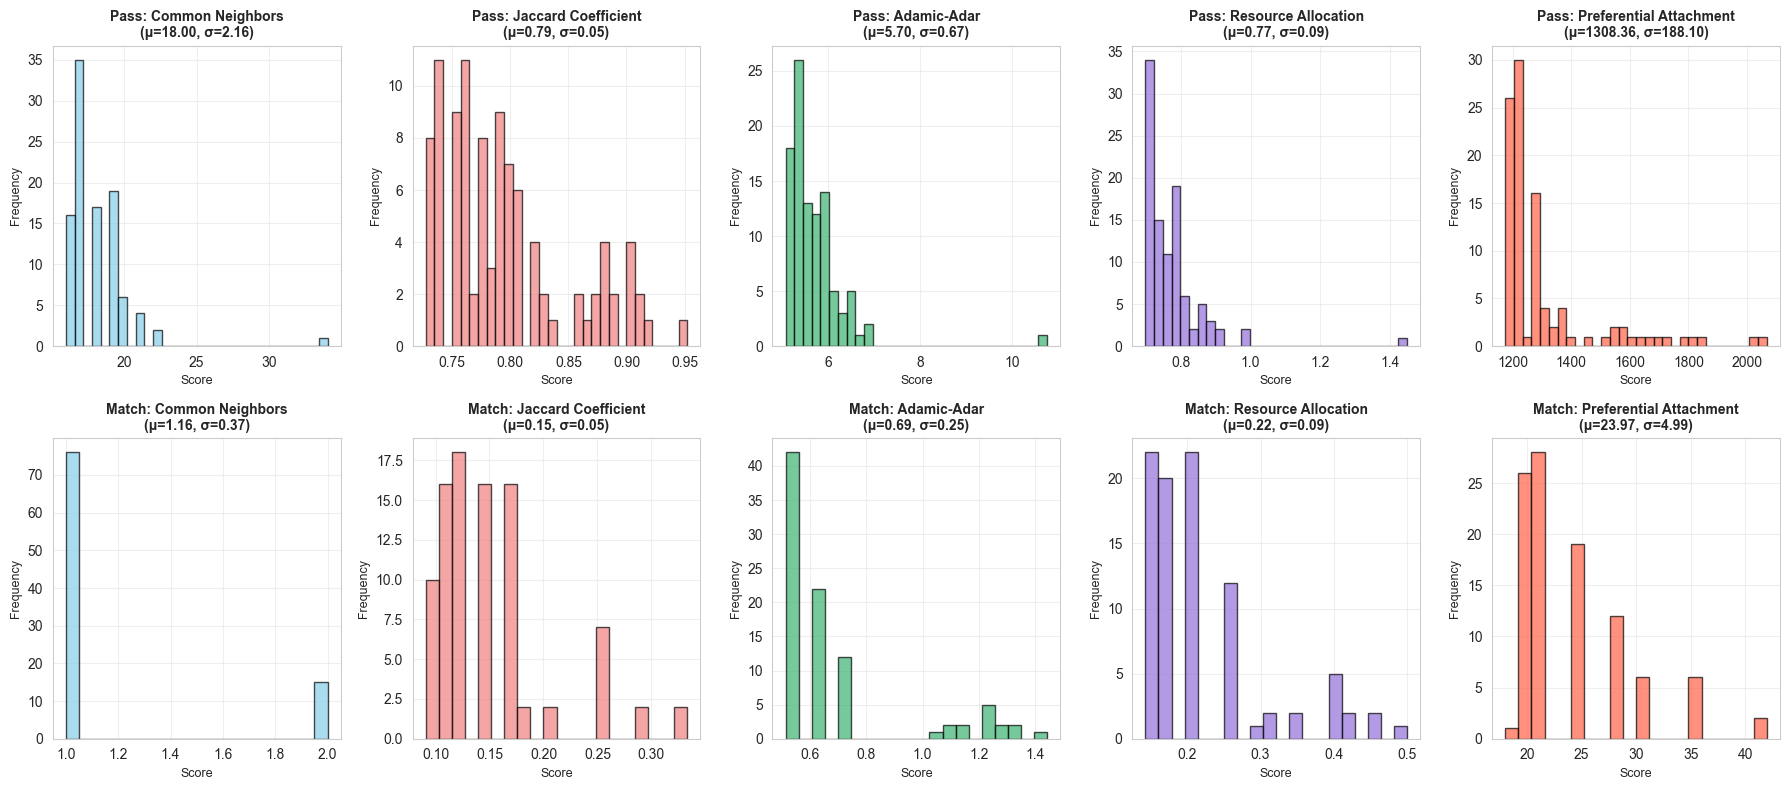

Saved: algorithm_score_distributions.png


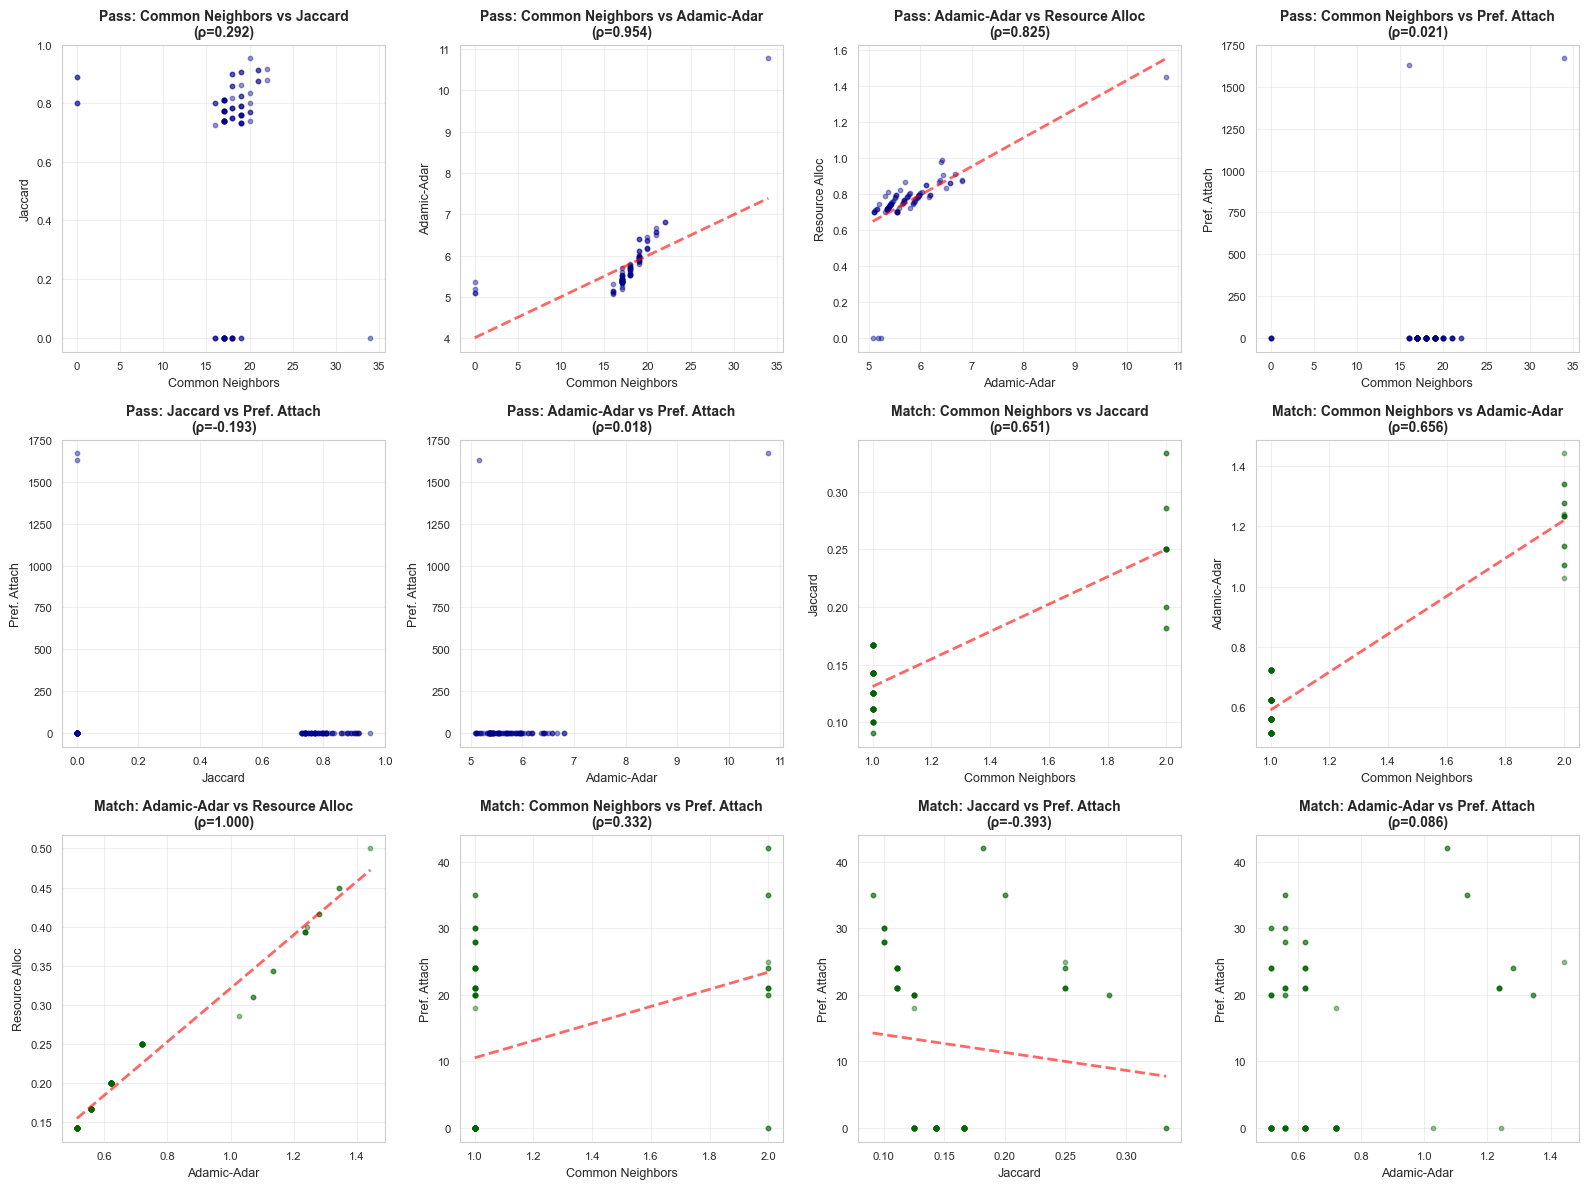

Saved: algorithm_pairwise_comparisons.png


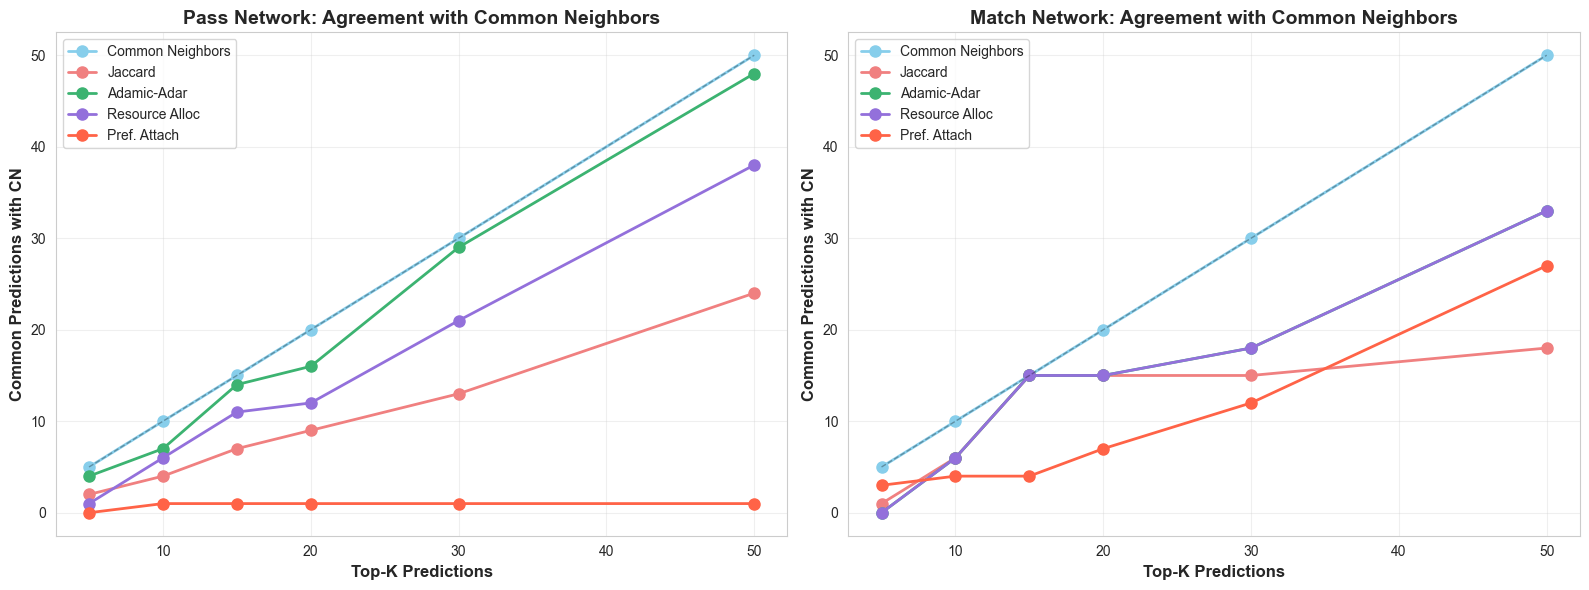

Saved: algorithm_top_k_agreement.png


In [44]:
figures_dir = project_root / 'reports' / 'figures' / 'LE8'

# ===== FIGURE 1: Overlap and Correlation Matrices (BOTH NETWORKS) =====
fig1, axes = plt.subplots(2, 2, figsize=(14, 12))

# pass network - Overlap heatmap
im1 = axes[0, 0].imshow(overlap_matrix_pass, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)
axes[0, 0].set_xticks(range(5))
axes[0, 0].set_yticks(range(5))
axes[0, 0].set_xticklabels(['CN', 'Jaccard', 'AA', 'RA', 'PA'], rotation=45)
axes[0, 0].set_yticklabels(['CN', 'Jaccard', 'AA', 'RA', 'PA'])
axes[0, 0].set_title('Pass Network: Top-20 Prediction Overlap\n(Jaccard Similarity)', fontsize=12, fontweight='bold')
axes[0, 0].grid(False)

for i in range(5):
    for j in range(5):
        axes[0, 0].text(j, i, f'{overlap_matrix_pass[i, j]:.2f}',
                       ha="center", va="center", 
                       color="black" if overlap_matrix_pass[i, j] < 0.5 else "white",
                       fontsize=10, fontweight='bold')

plt.colorbar(im1, ax=axes[0, 0], label='Overlap Score')

# pass network - Correlation heatmap
im2 = axes[0, 1].imshow(correlation_matrix_pass, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
axes[0, 1].set_xticks(range(5))
axes[0, 1].set_yticks(range(5))
axes[0, 1].set_xticklabels(['CN', 'Jaccard', 'AA', 'RA', 'PA'], rotation=45)
axes[0, 1].set_yticklabels(['CN', 'Jaccard', 'AA', 'RA', 'PA'])
axes[0, 1].set_title('Pass Network: Spearman Rank Correlation\n(on common predictions)', fontsize=12, fontweight='bold')
axes[0, 1].grid(False)

for i in range(5):
    for j in range(5):
        axes[0, 1].text(j, i, f'{correlation_matrix_pass[i, j]:.2f}',
                       ha="center", va="center", 
                       color="black" if abs(correlation_matrix_pass[i, j]) < 0.5 else "white",
                       fontsize=10, fontweight='bold')

plt.colorbar(im2, ax=axes[0, 1], label='Correlation')

# MATCH NETWORK - Overlap heatmap
im3 = axes[1, 0].imshow(overlap_matrix_wc, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)
axes[1, 0].set_xticks(range(5))
axes[1, 0].set_yticks(range(5))
axes[1, 0].set_xticklabels(['CN', 'Jaccard', 'AA', 'RA', 'PA'], rotation=45)
axes[1, 0].set_yticklabels(['CN', 'Jaccard', 'AA', 'RA', 'PA'])
axes[1, 0].set_title('Match Network: Top-20 Prediction Overlap\n(Jaccard Similarity)', fontsize=12, fontweight='bold')
axes[1, 0].grid(False)

for i in range(5):
    for j in range(5):
        axes[1, 0].text(j, i, f'{overlap_matrix_wc[i, j]:.2f}',
                       ha="center", va="center", 
                       color="black" if overlap_matrix_wc[i, j] < 0.5 else "white",
                       fontsize=10, fontweight='bold')

plt.colorbar(im3, ax=axes[1, 0], label='Overlap Score')

# MATCH NETWORK - Correlation heatmap
im4 = axes[1, 1].imshow(correlation_matrix_wc, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
axes[1, 1].set_xticks(range(5))
axes[1, 1].set_yticks(range(5))
axes[1, 1].set_xticklabels(['CN', 'Jaccard', 'AA', 'RA', 'PA'], rotation=45)
axes[1, 1].set_yticklabels(['CN', 'Jaccard', 'AA', 'RA', 'PA'])
axes[1, 1].set_title('Match Network: Spearman Rank Correlation\n(on common predictions)', fontsize=12, fontweight='bold')
axes[1, 1].grid(False)

for i in range(5):
    for j in range(5):
        axes[1, 1].text(j, i, f'{correlation_matrix_wc[i, j]:.2f}',
                       ha="center", va="center", 
                       color="black" if abs(correlation_matrix_wc[i, j]) < 0.5 else "white",
                       fontsize=10, fontweight='bold')

plt.colorbar(im4, ax=axes[1, 1], label='Correlation')

plt.tight_layout()
plt.savefig(figures_dir / 'algorithm_overlap_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: algorithm_overlap_correlation.png")


# ===== FIGURE 2: Score Distributions Comparison (BOTH NETWORKS) =====
fig2, axes = plt.subplots(2, 5, figsize=(18, 8))

# PASS NETWORK (top row)
score_data_pass = [
    ([s for _, _, s in predictions_cn], 'Common Neighbors', 'skyblue'),
    ([s for _, _, s in predictions_jc], 'Jaccard Coefficient', 'lightcoral'),
    ([s for _, _, s in predictions_aa], 'Adamic-Adar', 'mediumseagreen'),
    ([s for _, _, s in predictions_ra], 'Resource Allocation', 'mediumpurple'),
    ([s for _, _, s in predictions_pa], 'Preferential Attachment', 'tomato')
]

for idx, (scores, name, color) in enumerate(score_data_pass):
    axes[0, idx].hist(scores, bins=30, edgecolor='black', alpha=0.7, color=color)
    axes[0, idx].set_xlabel('Score', fontsize=9)
    axes[0, idx].set_ylabel('Frequency', fontsize=9)
    axes[0, idx].set_title(f'Pass: {name}\n(μ={np.mean(scores):.2f}, σ={np.std(scores):.2f})', 
                          fontweight='bold', fontsize=10)
    axes[0, idx].grid(True, alpha=0.3)

# MATCH NETWORK (bottom row)
score_data_wc = [
    ([s for _, _, s in predictions_cn_wc], 'Common Neighbors', 'skyblue'),
    ([s for _, _, s in predictions_jc_wc], 'Jaccard Coefficient', 'lightcoral'),
    ([s for _, _, s in predictions_aa_wc], 'Adamic-Adar', 'mediumseagreen'),
    ([s for _, _, s in predictions_ra_wc], 'Resource Allocation', 'mediumpurple'),
    ([s for _, _, s in predictions_pa_wc], 'Preferential Attachment', 'tomato')
]

for idx, (scores, name, color) in enumerate(score_data_wc):
    axes[1, idx].hist(scores, bins=20, edgecolor='black', alpha=0.7, color=color)
    axes[1, idx].set_xlabel('Score', fontsize=9)
    axes[1, idx].set_ylabel('Frequency', fontsize=9)
    axes[1, idx].set_title(f'Match: {name}\n(μ={np.mean(scores):.2f}, σ={np.std(scores):.2f})', 
                          fontweight='bold', fontsize=10)
    axes[1, idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(figures_dir / 'algorithm_score_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: algorithm_score_distributions.png")


# ===== FIGURE 3: Pairwise Algorithm Comparisons (BOTH NETWORKS) =====
fig3, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()  # Flatten to 1D array for easier indexing

comparisons = [
    ('CN', 'JC', 'Common Neighbors', 'Jaccard', 'skyblue', 'lightcoral'),
    ('CN', 'AA', 'Common Neighbors', 'Adamic-Adar', 'skyblue', 'mediumseagreen'),
    ('AA', 'RA', 'Adamic-Adar', 'Resource Alloc', 'mediumseagreen', 'mediumpurple'),
    ('CN', 'PA', 'Common Neighbors', 'Pref. Attach', 'skyblue', 'tomato'),
    ('JC', 'PA', 'Jaccard', 'Pref. Attach', 'lightcoral', 'tomato'),
    ('AA', 'PA', 'Adamic-Adar', 'Pref. Attach', 'mediumseagreen', 'tomato')
]

# Pass network (first 6 subplots: indices 0-5)
for idx, (method1, method2, name1, name2, color1, color2) in enumerate(comparisons):
    scores1 = [score_maps_pass[method1].get(pair, 0) for pair in common_pairs_pass[:300]]
    scores2 = [score_maps_pass[method2].get(pair, 0) for pair in common_pairs_pass[:300]]
    
    corr, _ = spearmanr(scores1, scores2)
    
    axes[idx].scatter(scores1, scores2, alpha=0.4, s=10, color='darkblue')
    axes[idx].set_xlabel(name1, fontsize=9)
    axes[idx].set_ylabel(name2, fontsize=9)
    axes[idx].set_title(f'Pass: {name1} vs {name2}\n(ρ={corr:.3f})', fontweight='bold', fontsize=10)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].tick_params(labelsize=8)
    
    if abs(corr) > 0.3:
        z = np.polyfit(scores1, scores2, 1)
        p = np.poly1d(z)
        x_trend = np.array([min(scores1), max(scores1)])
        axes[idx].plot(x_trend, p(x_trend), "r--", alpha=0.6, linewidth=2)

# Match network (next 6 subplots: indices 6-11)
for idx, (method1, method2, name1, name2, color1, color2) in enumerate(comparisons):
    plot_idx = idx + 6  # Offset by 6 for second set
    
    scores1 = [score_maps_wc[method1].get(pair, 0) for pair in common_pairs_wc[:300]]
    scores2 = [score_maps_wc[method2].get(pair, 0) for pair in common_pairs_wc[:300]]
    
    corr, _ = spearmanr(scores1, scores2)
    
    axes[plot_idx].scatter(scores1, scores2, alpha=0.4, s=10, color='darkgreen')
    axes[plot_idx].set_xlabel(name1, fontsize=9)
    axes[plot_idx].set_ylabel(name2, fontsize=9)
    axes[plot_idx].set_title(f'Match: {name1} vs {name2}\n(ρ={corr:.3f})', fontweight='bold', fontsize=10)
    axes[plot_idx].grid(True, alpha=0.3)
    axes[plot_idx].tick_params(labelsize=8)
    
    if abs(corr) > 0.3:
        z = np.polyfit(scores1, scores2, 1)
        p = np.poly1d(z)
        x_trend = np.array([min(scores1), max(scores1)])
        axes[plot_idx].plot(x_trend, p(x_trend), "r--", alpha=0.6, linewidth=2)

plt.tight_layout()
plt.savefig(figures_dir / 'algorithm_pairwise_comparisons.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: algorithm_pairwise_comparisons.png")


# ===== FIGURE 4: Top-K Agreement Analysis (BOTH NETWORKS) =====
fig4, axes = plt.subplots(1, 2, figsize=(16, 6))

k_values = [5, 10, 15, 20, 30, 50]
colors = ['skyblue', 'lightcoral', 'mediumseagreen', 'mediumpurple', 'tomato']

# PASS NETWORK
overlap_by_k_pass = {name: [] for name in algo_names}

for k in k_values:
    baseline_pairs = get_top_pairs(predictions_cn, k)
    
    for preds, name in [
        (predictions_cn, 'Common Neighbors'),
        (predictions_jc, 'Jaccard'),
        (predictions_aa, 'Adamic-Adar'),
        (predictions_ra, 'Resource Alloc'),
        (predictions_pa, 'Pref. Attach')
    ]:
        algo_pairs = get_top_pairs(preds, k)
        overlap_count = len(baseline_pairs.intersection(algo_pairs))
        overlap_by_k_pass[name].append(overlap_count)

for i, (name, color) in enumerate(zip(algo_names, colors)):
    axes[0].plot(k_values, overlap_by_k_pass[name], marker='o', linewidth=2, 
                markersize=8, label=name, color=color)

axes[0].set_xlabel('Top-K Predictions', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Common Predictions with CN', fontsize=12, fontweight='bold')
axes[0].set_title('Pass Network: Agreement with Common Neighbors', 
                 fontsize=14, fontweight='bold')
axes[0].legend(loc='upper left', fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].plot(k_values, k_values, 'k--', alpha=0.3, linewidth=1)

# MATCH NETWORK
overlap_by_k_wc = {name: [] for name in algo_names}

for k in k_values:
    baseline_pairs = get_top_pairs(predictions_cn_wc, k)
    
    for preds, name in [
        (predictions_cn_wc, 'Common Neighbors'),
        (predictions_jc_wc, 'Jaccard'),
        (predictions_aa_wc, 'Adamic-Adar'),
        (predictions_ra_wc, 'Resource Alloc'),
        (predictions_pa_wc, 'Pref. Attach')
    ]:
        algo_pairs = get_top_pairs(preds, k)
        overlap_count = len(baseline_pairs.intersection(algo_pairs))
        overlap_by_k_wc[name].append(overlap_count)

for i, (name, color) in enumerate(zip(algo_names, colors)):
    axes[1].plot(k_values, overlap_by_k_wc[name], marker='o', linewidth=2, 
                markersize=8, label=name, color=color)

axes[1].set_xlabel('Top-K Predictions', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Common Predictions with CN', fontsize=12, fontweight='bold')
axes[1].set_title('Match Network: Agreement with Common Neighbors', 
                 fontsize=14, fontweight='bold')
axes[1].legend(loc='upper left', fontsize=10)
axes[1].grid(True, alpha=0.3)
axes[1].plot(k_values, k_values, 'k--', alpha=0.3, linewidth=1)

plt.tight_layout()
plt.savefig(figures_dir / 'algorithm_top_k_agreement.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: algorithm_top_k_agreement.png")

# Conclusion

Overall, the link prediction results reveal that different methods capture distinct but complementary structures in football networks, with notable differences between pass and match networks.

## Pass Network Findings

In the pass network, **neighborhood-based methods** (Common Neighbors, Adamic-Adar, and Resource Allocation) show high agreement (overlap 0.43-0.67) and strong rank correlations (0.66-0.95), indicating they capture similar local clustering patterns among players. **Jaccard Coefficient** produces more diverse rankings (overlap ~0.29-0.48) due to its normalization effect, making it particularly valuable when player activity levels vary widely. **Preferential Attachment** stands distinctly apart with minimal overlap (0.00-0.03) and moderate to negative correlations (-0.43 with Jaccard, 0.57 with CN), emphasizing global popularity over local tactical compatibility.

## Match Network Findings

The match network shows **higher overall agreement** among neighborhood-based methods, with CN, Jaccard, AA, and RA all achieving 0.60 overlap with each other—much higher than in the pass network. This reflects the tournament's structured nature where teams sharing opponents are more uniformly similar. Rank correlations are also consistently high (0.49-1.00) among these methods, with AA and RA showing **perfect correlation (1.00)**, indicating they produce identical rankings in this context. **Preferential Attachment** again shows the lowest agreement (0.11-0.21 overlap) and negative correlation with Jaccard (-0.47), confirming it captures a fundamentally different aspect: team popularity and match frequency rather than tactical or competitive similarity.

## Key Insights

The **pass network** benefits from method diversity—combining normalized (Jaccard), weighted (AA/RA), and popularity-based (PA) approaches captures tactical partnerships, specialist connections, and star player dynamics. The **match network's** higher homogeneity among neighborhood methods suggests simpler patterns, where tournament structure dominates and popularity-based prediction complements structural approaches. Together, these results demonstrate that **ensemble approaches** combining local similarity and global popularity metrics provide the most complete view of link formation across different football network types.